# A Looped Vision Transformer That Knows When to Stop

> **Chapter 4 project:** Replace a stack of different transformer blocks with **one block applied again and again**, teach the early loops with the model's own final answer, and let each image decide how many loops it needs.

## Why this notebook matters

Every Vision Transformer in this chapter stacks *different* blocks. ViT-S has 12 blocks, and each one has its own weights. A **looped transformer** asks a simple question: what if we kept only one block and ran it 6 times?

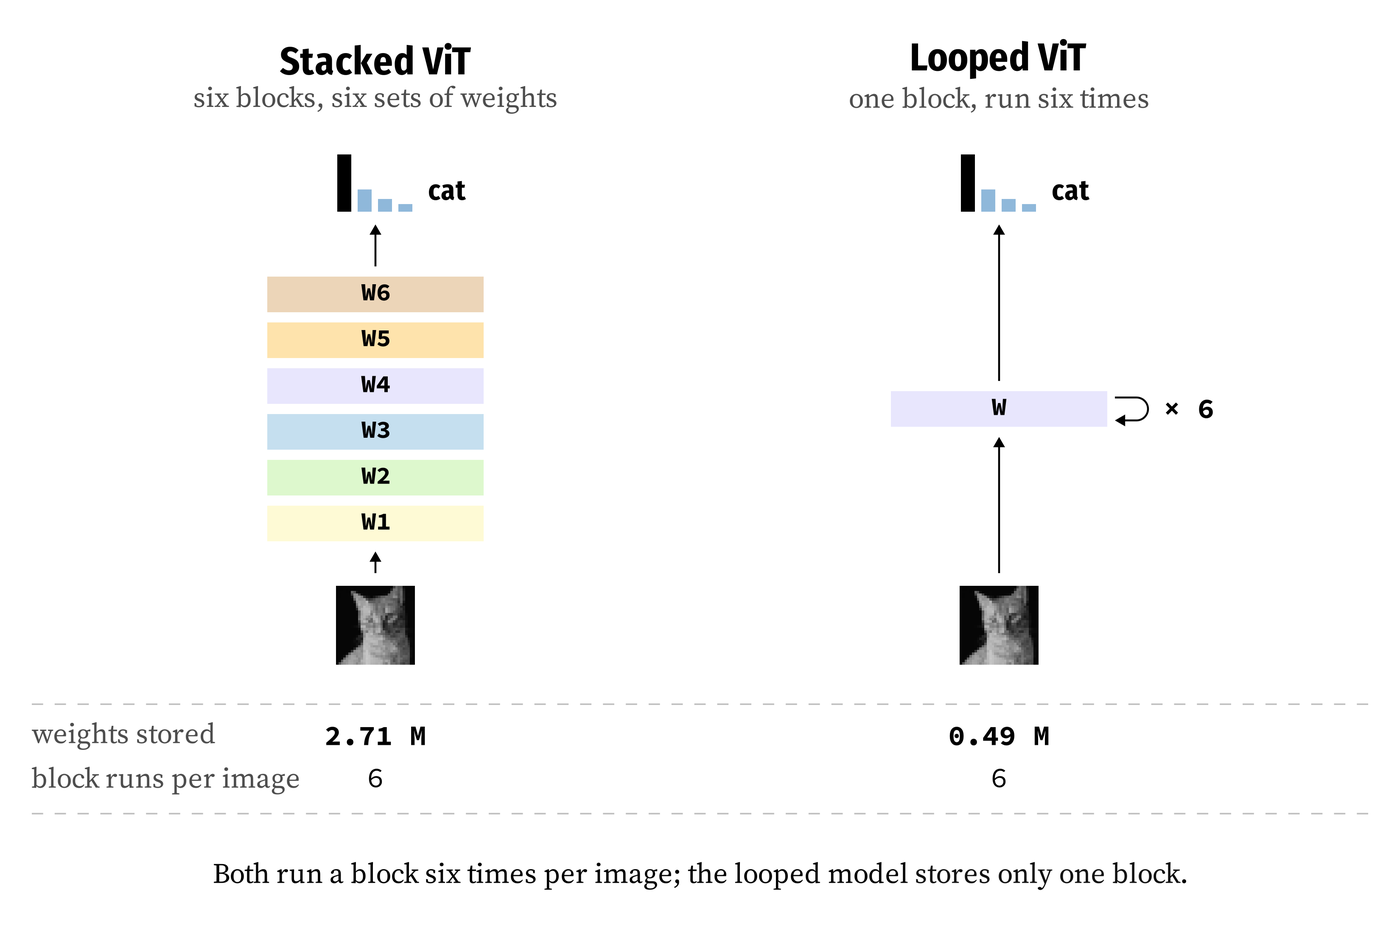

Looping is a fast-moving research topic in 2025-2026, first in language models and now in vision. It is also a neat way to revisit everything this chapter taught: model cost (section 4.1), distillation (sections 4.2-4.4), and how to measure efficiency honestly (section 4.15).

## What you will learn

By the end of this notebook you will be able to:

- build a looped ViT from a standard ViT by changing one `for` loop, plus three small additions;
- explain why **fewer parameters do not mean less compute**, and show it with your own measurements;
- train a model that gives an answer after **every** loop, and use that to **stop early** on easy images;
- apply **self-distillation**, the DeiT idea of a teacher, using the model's own last loop as the teacher;
- read an accuracy-versus-compute curve and choose an operating point on validation data.

## The three claims we will test

| # | Claim | How we test it |
| --- | --- | --- |
| 1 | **Looping saves parameters, not compute.** | Count parameters and GMACs before training (section 6) |
| 2 | **Stopping early is what saves compute.** | Exit when confident and measure images per second (sections 11-12) |
| 3 | **Self-distillation makes stopping early work better.** | Compare exit curves with and without it (sections 11-13) |

## The five experiments

Every run uses the same data, width, recipe, and seed. Each one changes a single thing, so any difference in the results has one cause.

| ID | Model | What changes | The question it answers |
| --- | --- | --- | --- |
| **A0** | Stacked ViT, 6 different blocks | nothing (baseline) | What does a normal ViT achieve? |
| **A1** | Looped ViT, 1 block x 6 loops | blocks are shared | Can one block replace six? |
| **A2** | One-block ViT, run once | no looping | Same parameters as A1. Does looping itself buy accuracy? |
| **A4** | Looped ViT, loss on last loop only | training objective | Why must every loop be trained? |
| **A9** | Looped ViT + self-distillation | training objective | Does the last loop make a good teacher? |

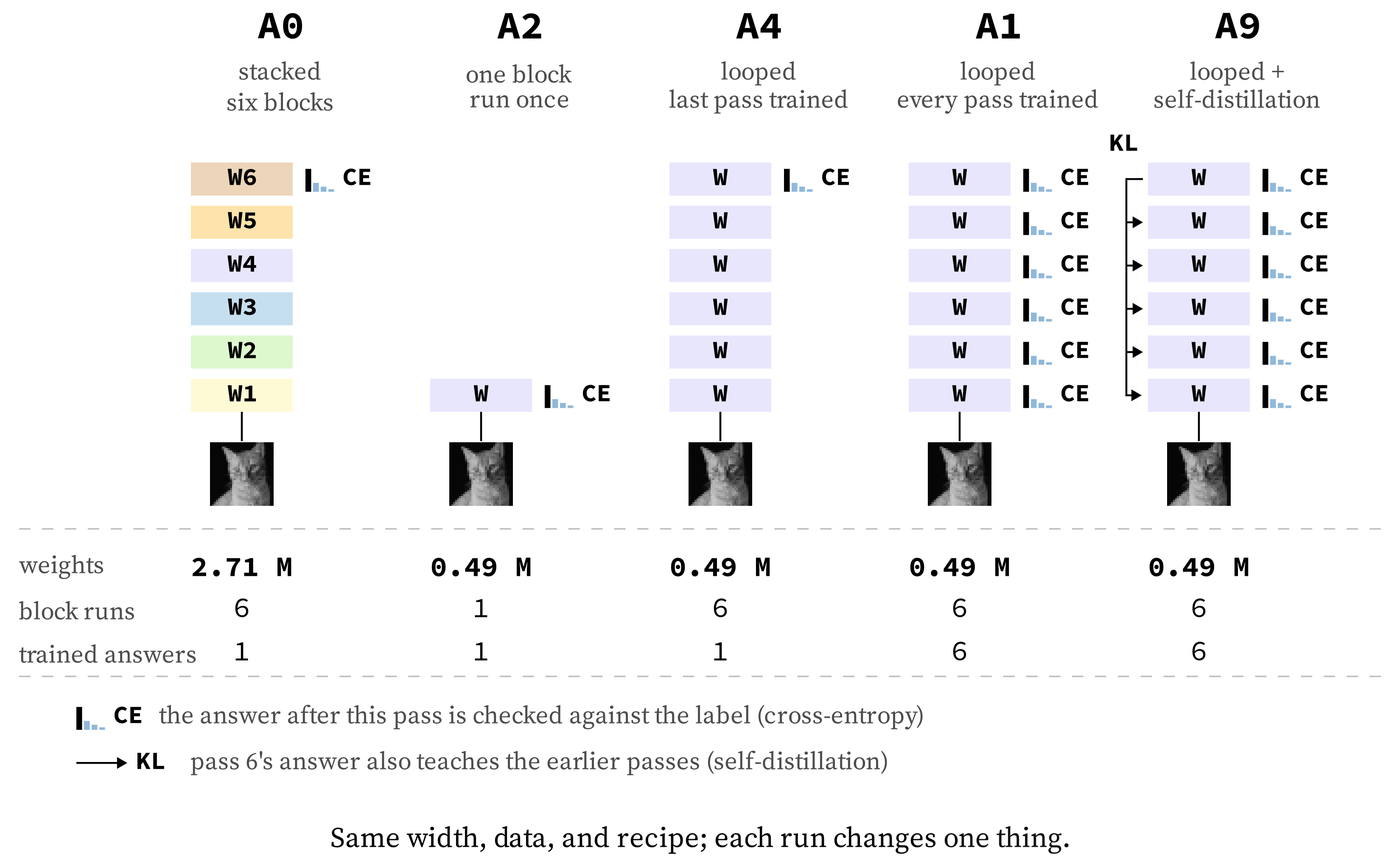

## Results at a glance

The outputs saved in this notebook come from one full run on a T4 GPU (CIFAR-100 test set). Your numbers will differ slightly.

| Model | Params | GMACs per image | Test top-1 | Images/s |
| --- | ---: | ---: | ---: | ---: |
| A0 stacked ViT, 6 blocks | 2.71M | 0.183 | 58.9% | 5,892 |
| A2 one block, run once | 0.49M | 0.031 | 31.7% | 34,180 |
| A4 looped, all 6 loops | 0.49M | 0.183 | 55.3% | 5,964 |
| A1 looped, all 6 loops | 0.49M | 0.183 | 53.1% | 5,920 |
| **A9 looped + self-distillation, early exit (at most 4 loops)** | **0.49M** | **0.107** | **52.7%** | **9,604** |

- **Parameters:** every looped model stores **82% fewer parameters** than A0 (0.49M instead of 2.71M, 5.5x smaller). At full depth the best looped model, A4, is about 3.5 points behind A0.
- **Compute:** at full depth a looped model costs exactly as much as A0. Only stopping early cuts compute. The last row runs **3.5 block passes per image instead of 6**, uses **1.7x fewer GMACs** and runs **1.6x faster** than A0, for about 6 points of accuracy.
- **Looping itself works:** A1 and A2 store the same weights, but looping lifts test accuracy from 31.7% to 53.1%.

> **NOTE** How robust are these numbers? We also trained every model with five different seeds. Mean test accuracy (± standard deviation): A0 58.5 ± 0.4%, A4 55.5 ± 0.4%, A1 53.6 ± 0.3%, A9 53.5 ± 0.7%, A2 31.0 ± 0.2%. With early exit, A9 averaged 3.7 block passes for 53.4%. The single run saved here falls inside these ranges.

## Roadmap

| Section | What you do | What you get |
| --- | --- | --- |
| 1-3 | Set up the device, settings, and data | CIFAR-100 split into train, validation, and test |
| 4-5 | Build the stacked and looped ViTs | Two models that differ only in their blocks |
| 6 | Measure before training | Parameters and GMACs for A0, A1, A2 |
| 7-8 | Write the three training objectives and the training loop | Self-distillation in about ten lines |
| 9 | Train all five runs | Five checkpoints and their learning curves |
| 10 | Accuracy after every loop | Where each model's accuracy comes from |
| 11-12 | Early exit, simulated and for real | An accuracy-versus-compute curve and a test-set results table |
| 13-14 | Explore | Easy and hard images, and an interactive confidence viewer |
| 15 | Wrap up | Conclusions, limits, and experiments to try |

## Compute budget

| Hardware | Settings | Time |
| --- | --- | --- |
| T4 GPU with 2 CPU cores (as in free Colab) | defaults (60 epochs, 5 runs) | **measured:** about 16 min per run, 80 min of training in total |
| Apple Silicon laptop (MPS) | defaults | estimate: roughly 2-3x the T4 time |
| CPU only | `TRAIN_SUBSET = 5000`, `EPOCHS = 3` | estimate: a few minutes per run, for following the workflow only |

> **NOTE** With 2 CPU cores, preparing the augmented images sets the pace, not the GPU: even A2, which does a sixth of the block work, takes about 16 minutes. The first run also downloads CIFAR-100 (169 MB) once; on a slow connection this can take several minutes.

> **TIP** Each finished run is saved to `./checkpoints`. If Colab disconnects, reconnect and choose **Runtime > Run all**: finished runs are loaded instead of retrained, and training continues with the next run.

## Before you start

You should be comfortable with the ViT from chapter 3 (patches, class token, positional embeddings) and with knowledge distillation from section 4.3 (soft targets and temperature). In Colab, select **Runtime > Change runtime type > T4 GPU** before running anything.

## 1. Imports and device

The notebook needs only PyTorch, torchvision, and matplotlib.

| Import | Role |
| --- | --- |
| `torch`, `torch.nn`, `torch.nn.functional` | Tensors, layers, and loss functions |
| `DataLoader`, `Subset` | Mini-batches and the train/validation split |
| `FlopCounterMode` | Counts the operations in one forward pass (PyTorch 2.1 and later), so we need no extra profiling library |
| `datasets`, `transforms` | CIFAR download and image preprocessing |
| `matplotlib` | Every plot in the notebook |

The device cell picks the fastest hardware available: an NVIDIA GPU (`cuda`), an Apple Silicon GPU (`mps`), or the CPU. Every model and batch must live on the same device.

In [1]:
#@title Imports
import os, time
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torch.utils.flop_counter import FlopCounterMode
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

In [2]:
#@title Device
if torch.cuda.is_available():
    device = 'cuda'
elif torch.backends.mps.is_available():
    device = 'mps'
else:
    device = 'cpu'
print(device)

cuda


## 2. Hyperparameters

All five runs share these settings. Keeping them in one cell makes it easy to see what is held fixed, and to change one thing at a time.

| Constant | Value | Meaning |
| --- | ---: | --- |
| `DATASET` | `'cifar100'` | `'cifar100'` (100 classes, default) or `'cifar10'` (10 classes, easier) |
| `DEPTH` | 6 | Blocks in the stacked ViT, and loops in the looped ViT |
| `EMBED_DIM` | 192 | Width of every token vector (the same width as ViT-Tiny) |
| `HEADS` | 3 | Attention heads per block |
| `MLP_RATIO` | 4 | Hidden width of the feed-forward layer, as a multiple of `EMBED_DIM` |
| `PATCH_SIZE` | 4 | Height and width of each square patch |
| `EPOCHS` | 60 | Training passes over the training split (small models need more passes once augmentation is strong) |
| `KD_TEMPERATURE` | 2 | Softens the teacher's probabilities in self-distillation (section 4.3) |
| `KD_WEIGHT` | 0.5 | How much the self-distillation term counts next to the label loss (0.5 won our sweep; 2 hurt) |
| `TRAIN_SUBSET` | `None` | Set to a number such as 5000 for a quick CPU run |

### Token geometry

CIFAR images are 32 by 32 pixels. With 4 by 4 patches we get an 8 by 8 grid:

$$
N = \left(\frac{32}{4}\right)^2 = 64 \text{ patch tokens} \quad (+1 \text{ class token} = 65)
$$

### Why CIFAR-100 and not CIFAR-10?

Both datasets have 32 by 32 images and cost exactly the same compute. CIFAR-100 is a better test for this project for three reasons:

- **More images need several loops.** With 100 classes, many of them similar (maple and oak, boy and girl, leopard and tiger), fewer images are easy enough to exit at loop 1, so early exit has real decisions to make.
- **Soft labels carry more information.** A teacher that says "70% leopard, 20% tiger, 5% lion" teaches more than a 10-class teacher can, which is exactly what self-distillation relies on.
- **It matches the chapter's benchmark,** which also uses CIFAR-100.

> **TIP** To follow the whole notebook quickly on a CPU, set `TRAIN_SUBSET = 5000` and `EPOCHS = 3`. Accuracy will be low, but every plot and table will appear.

**In pictures:** what the next cell does.

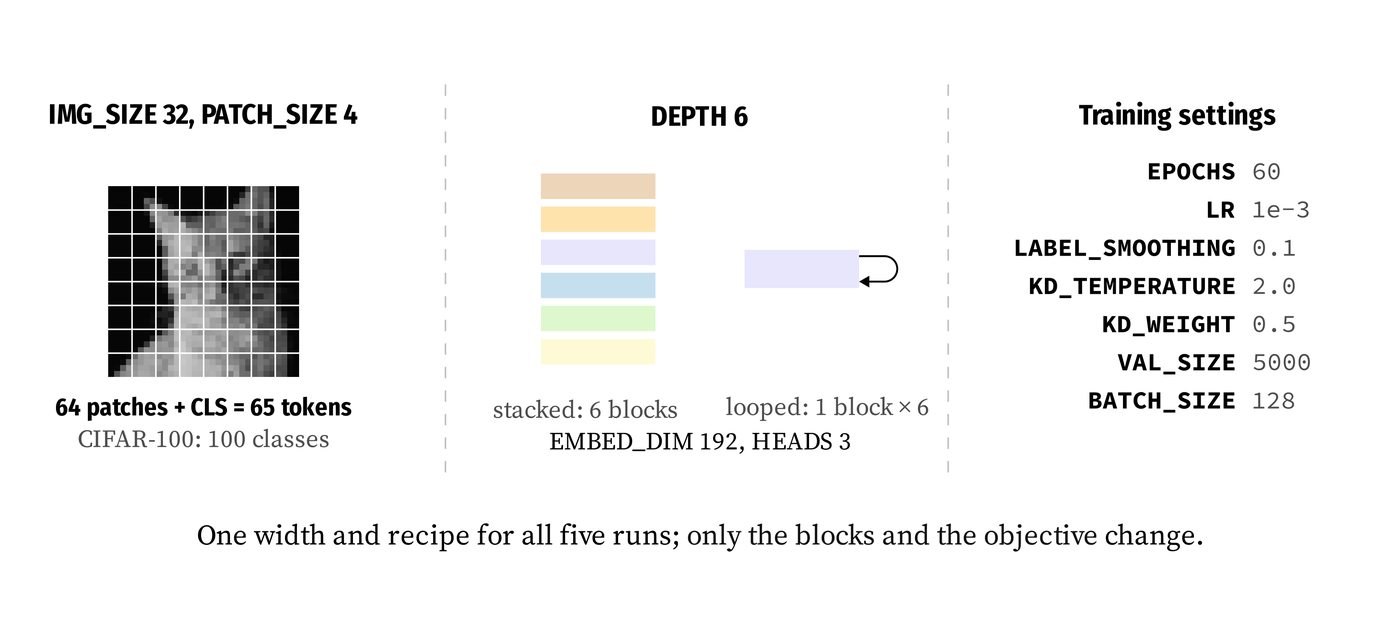

In [3]:
#@title Variables
DATASET = 'cifar100'
SEED = 42
IMG_SIZE = 32
PATCH_SIZE = 4
CHANNELS = 3
CLASSES = 100 if DATASET == 'cifar100' else 10
EMBED_DIM = 192
HEADS = 3
MLP_RATIO = 4
DEPTH = 6
BATCH_SIZE = 128
EPOCHS = 60
LR = 1e-3
WEIGHT_DECAY = 0.05
LABEL_SMOOTHING = 0.1
KD_TEMPERATURE = 2.0
KD_WEIGHT = 0.5
VAL_SIZE = 5000
TRAIN_SUBSET = None
NUM_WORKERS = 2
CHECKPOINT_DIR = './checkpoints'

## 3. Data: train, validation, and test splits

We keep the same discipline as the chapter's benchmark:

```text
CIFAR-100 training set (50,000 images)
 |-- train        45,000   -> learn the weights
 |-- validation    5,000   -> pick the best epoch, pick the early-exit threshold
CIFAR-100 test set (10,000 images)
 |-- test         10,000   -> used once, at the very end
```

Training images get a random crop (with 4 pixels of padding) and a random horizontal flip, so the model sees slightly different versions of each image every epoch. Validation and test images are only converted to tensors and normalized, so their scores are deterministic.

The split uses a fixed random generator, so every run sees exactly the same 45,000 training images.

> **WARNING** Never use the test set to choose anything, including the best epoch or the threshold. If you do, the test score stops being an honest estimate of how the model will do on new images.

**In pictures:** what the next cell does.

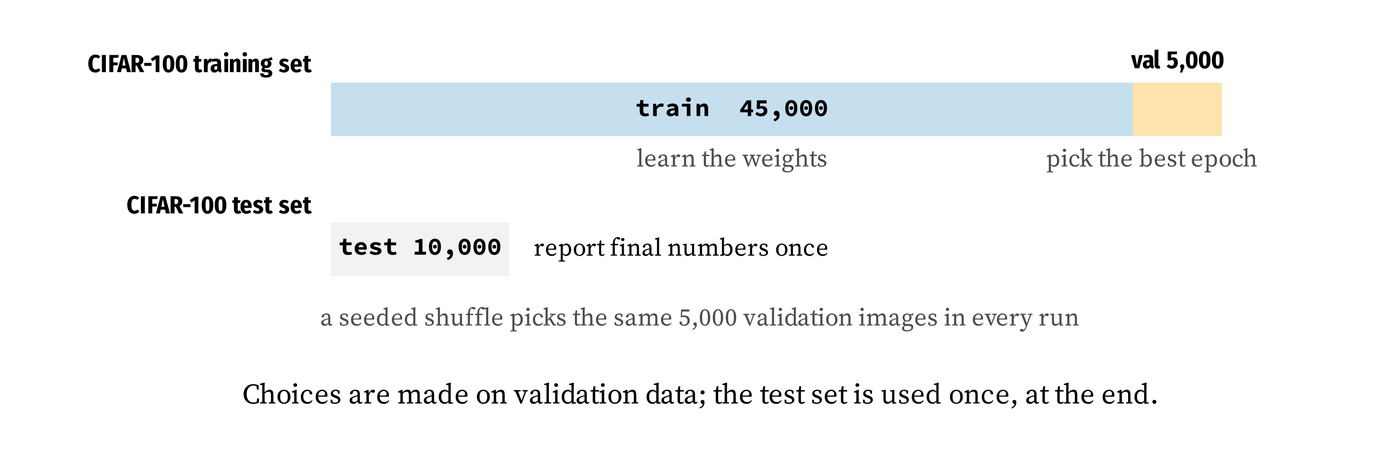
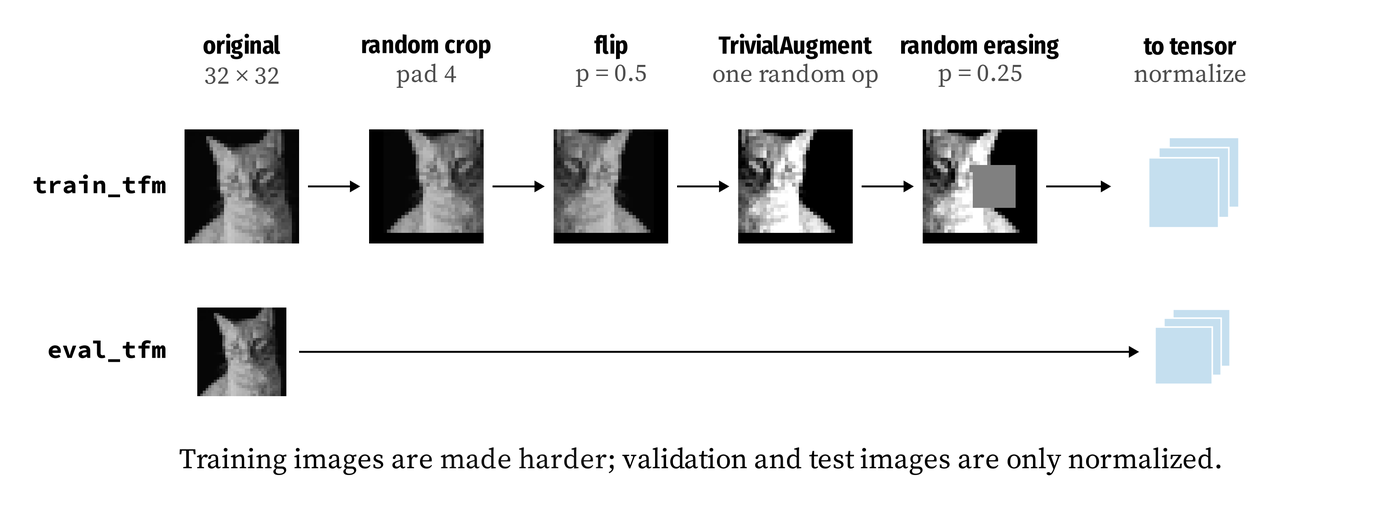

In [4]:
#@title Data
if DATASET == 'cifar100':
    Dataset, mean, std = datasets.CIFAR100, (0.5071, 0.4865, 0.4409), (0.2673, 0.2564, 0.2762)
else:
    Dataset, mean, std = datasets.CIFAR10, (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)

train_tfm = transforms.Compose([
    transforms.RandomCrop(IMG_SIZE, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.TrivialAugmentWide(),                                       #A
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
    transforms.RandomErasing(p=0.25),                                      #B
])
eval_tfm = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)])

train_full = Dataset('./data', train=True, download=True, transform=train_tfm)
val_full = Dataset('./data', train=True, download=True, transform=eval_tfm)
test = Dataset('./data', train=False, download=True, transform=eval_tfm)
class_names = test.classes

perm = torch.randperm(len(train_full), generator=torch.Generator().manual_seed(SEED))
val_idx, train_idx = perm[:VAL_SIZE], perm[VAL_SIZE:]
if TRAIN_SUBSET:
    train_idx = train_idx[:TRAIN_SUBSET]
train = Subset(train_full, train_idx.tolist())
val = Subset(val_full, val_idx.tolist())

loader_args = dict(num_workers=NUM_WORKERS, pin_memory=(device == 'cuda'))
train_dl = DataLoader(train, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, **loader_args)
val_dl = DataLoader(val, batch_size=256, **loader_args)
test_dl = DataLoader(test, batch_size=256, **loader_args)
print(f"{DATASET}: train {len(train)}  val {len(val)}  test {len(test)}")

cifar100: train 45000  val 5000  test 10000


Annotations: **#A** TrivialAugment applies one randomly chosen image operation (a rotation, a colour shift, sharpening, and so on) at a random strength to every training image. **#B** random erasing blanks out a random rectangle in a quarter of the training images. Both make the training images harder to memorize.

> **NOTE** We chose this recipe with an ablation sweep, on validation data only. With crops and flips alone, the stacked ViT memorized the training set (98.5% right on training images, 53% on validation). Stronger augmentation added about 5 points to every model, but only with 60 epochs: at 30 epochs the small looped models did *worse*, because 0.49M parameters need more passes to fit harder examples.

## 4. The shared parts: patch embedding, class token, and head

Every model in this notebook turns an image into tokens in exactly the same way, and every model reads the class token to classify. Only the middle, the transformer blocks, will differ. Putting the shared parts in one base class makes that difference easy to see.

```text
Input image                [B, 3, 32, 32]
    -> 4 by 4 patch projection
Patch-token sequence       [B, 64, 192]
    -> prepend class token, add positions
Full token sequence        [B, 65, 192]
    -> transformer blocks (stacked or looped)
    -> LayerNorm on the class token, then a linear head
Logits                     [B, CLASSES]
```

| Piece | What it does |
| --- | --- |
| `PatchEmbed` | A convolution with kernel size and stride equal to the patch size cuts the image into patches and projects each one to a 192-number vector |
| `cls` | A learned class token placed in front of the patch tokens; its final value summarizes the image |
| `pos` | Learned positional embeddings, one per token, so the model knows where each patch came from |
| `classify` | LayerNorm plus a linear layer that turns the class token into one score per class |
| `make_block` | One transformer block: multi-head attention, feed-forward network, LayerNorm, and residual connections from chapter 2 |

We use PyTorch's built-in `nn.TransformerEncoderLayer` for each block, so the notebook can focus on how blocks are *arranged* rather than how they are built. `norm_first=True` gives the pre-norm layout that ViT uses.

**In pictures:** what the next cell does.

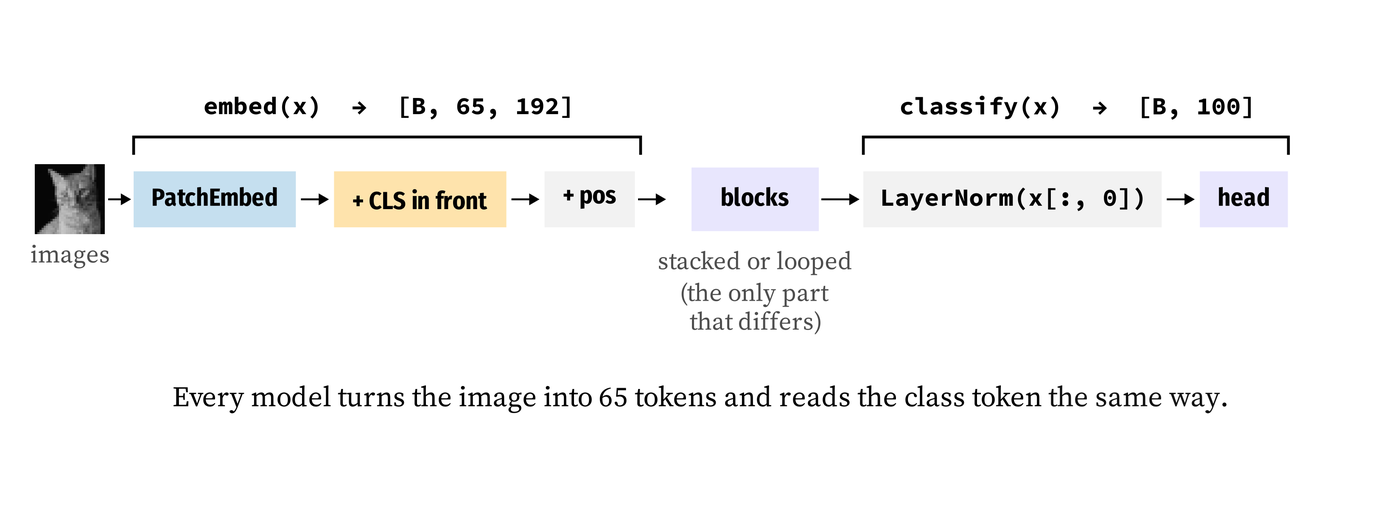

In [5]:
#@title Shared ViT parts
class PatchEmbed(nn.Module):
    def __init__(self):
        super().__init__()
        self.proj = nn.Conv2d(CHANNELS, EMBED_DIM, PATCH_SIZE, PATCH_SIZE)
        self.n = (IMG_SIZE // PATCH_SIZE) ** 2
    def forward(self, x):
        return self.proj(x).flatten(2).transpose(1, 2)

def make_block():
    return nn.TransformerEncoderLayer(
        EMBED_DIM, HEADS, EMBED_DIM * MLP_RATIO, dropout=0.0,
        activation='gelu', batch_first=True, norm_first=True)

class ViTBase(nn.Module):
    def __init__(self):
        super().__init__()
        self.patch = PatchEmbed()
        self.cls = nn.Parameter(torch.zeros(1, 1, EMBED_DIM))
        self.pos = nn.Parameter(torch.randn(1, self.patch.n + 1, EMBED_DIM) * 0.02)
        self.norm = nn.LayerNorm(EMBED_DIM)
        self.head = nn.Linear(EMBED_DIM, CLASSES)
    def embed(self, x):
        x = self.patch(x)
        cls = self.cls.expand(x.size(0), -1, -1)
        return torch.cat([cls, x], dim=1) + self.pos
    def classify(self, x):
        return self.head(self.norm(x[:, 0]))

## 5. Two ways to arrange the blocks

The **stacked ViT** is the ViT from chapter 3: a list of different blocks, applied once each. With `depth=6` it is our baseline **A0**. With `depth=1` it is **A2**, a model with exactly the looped model's block parameters that runs its block only once.

The **looped ViT** keeps a single block and calls it `DEPTH` times inside a `for` loop. That `for` loop is the whole architectural change:

```python
# Stacked: 6 different blocks          # Looped: 1 block, used 6 times
for block in self.blocks:              for t in range(6):
    x = block(x)                           x = self.block(x)
```

A bare loop already works, but three small additions make the looped model accurate and able to stop early.

| Addition | Code | Why it is needed |
| --- | --- | --- |
| **1. Step embedding** | `x = self.block(x + self.step_embed(t))` | The block cannot tell loop 1 from loop 5 on its own |
| **2. Prediction after every loop** | `logits.append(self.classify(x))` | Gives an answer at every loop, which early exit needs |
| **3. Loss at every loop** | average cross-entropy over all loops (section 7) | Without it, only the last loop gives good answers |

Here is the looped forward pass with all three in place:

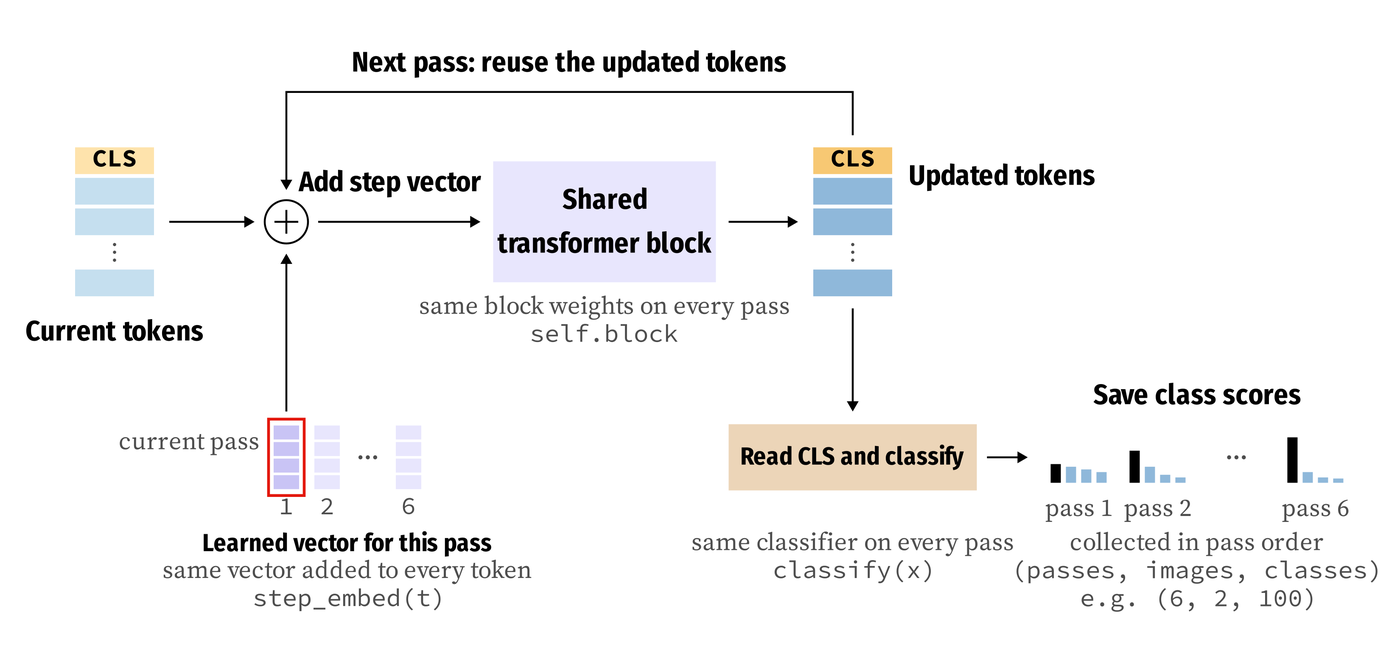

The figure, like the chapter, calls each loop a *pass*: one run of the shared block.

### Addition 1: the step embedding

The block sees the same weights on every loop, so it cannot tell whether this is loop 1 or loop 5, even though early loops should look at local detail and later loops should combine the whole image. We add a small learned vector for each loop number to the tokens.

| | Tells the model | Added to |
| --- | --- | --- |
| Positional embedding (chapter 3) | *where* a token is in the image | each patch token, once |
| Step embedding (this notebook) | *when* this is in the loop | every token, on every loop |

It costs only `DEPTH x EMBED_DIM` = 6 x 192 = 1,152 extra numbers. Research on looped ViTs found that a shared block behaves differently at each step, and this vector gives it a cheap way to do so.

### Addition 2: a prediction after every loop

The same `classify` head reads the class token after each loop. `forward_all` returns a stack of logits, one per loop, with shape `[loops, B, CLASSES]`. `forward` simply returns the last one, so the looped ViT can be used anywhere a normal model is expected.

### Addition 3 and the early-exit rule

Addition 3, a loss at every loop, lives in the training code in section 7, together with self-distillation. At inference, a fourth piece, the **early-exit rule** in sections 11 and 12, uses the per-loop predictions to stop as soon as the model is confident.

> **NOTE** If we run the looped model for more loops than it has step embeddings, `step_embed` reuses the last one. That lets us ask in section 10 what happens when a model "thinks longer" than it was trained to.

**In pictures:** what the next cell does.

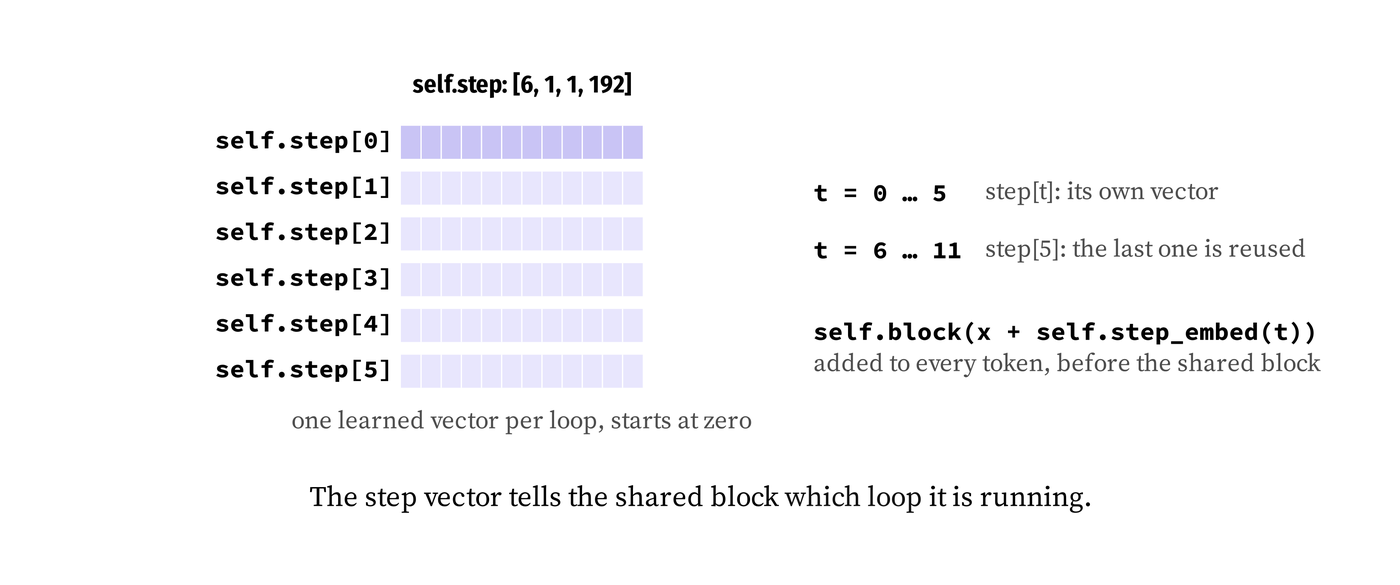

In [6]:
#@title Stacked and looped ViTs
class StackedViT(ViTBase):
    def __init__(self, depth=DEPTH):
        super().__init__()
        self.blocks = nn.ModuleList([make_block() for _ in range(depth)])  #A
    def forward(self, x):
        x = self.embed(x)
        for block in self.blocks:
            x = block(x)
        return self.classify(x)

class LoopedViT(ViTBase):
    def __init__(self, loops=DEPTH):
        super().__init__()
        self.loops = loops
        self.block = make_block()                                          #B
        self.step = nn.Parameter(torch.zeros(loops, 1, 1, EMBED_DIM))      #C
    def step_embed(self, t):
        return self.step[min(t, self.loops - 1)]
    def forward_all(self, x, loops=None):
        x = self.embed(x)
        logits = []
        for t in range(loops or self.loops):
            x = self.block(x + self.step_embed(t))                         #D
            logits.append(self.classify(x))                                #E
        return torch.stack(logits)
    def forward(self, x, loops=None):
        return self.forward_all(x, loops)[-1]

Annotations: **#A** a list of different blocks, each with its own weights. **#B** one block, shared by every loop. **#C** one learned step vector per loop (addition 1). **#D** the same block runs again on the updated tokens, plus the step vector for this loop (addition 1). **#E** the shared head makes a prediction after every loop (addition 2).

### Quick shape check

Before measuring anything, confirm that the models produce the shapes we expect. The stacked model returns one set of logits. The looped model's `forward_all` returns one set per loop.

**In pictures:** what the next cell does.

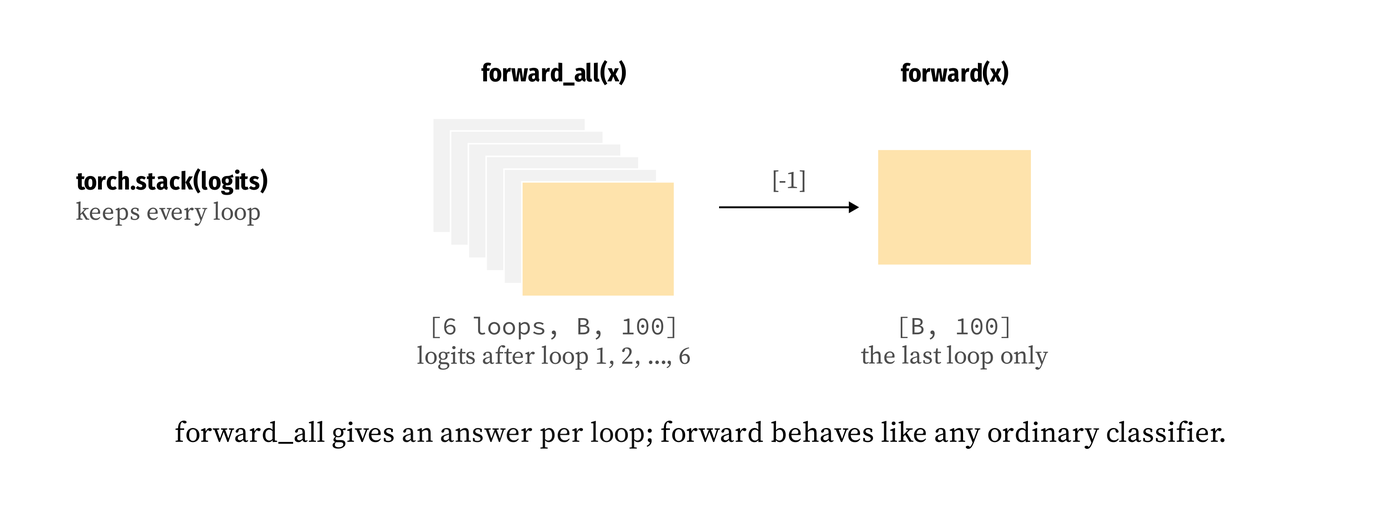

In [7]:
#@title Quick shape check
x = torch.randn(2, CHANNELS, IMG_SIZE, IMG_SIZE, device=device)
print('stacked forward     :', tuple(StackedViT(DEPTH).to(device)(x).shape), '  [batch, classes]')
print('looped forward_all  :', tuple(LoopedViT(DEPTH).to(device).forward_all(x).shape), '  [loops, batch, classes]')
print('looped, 12 loops    :', tuple(LoopedViT(DEPTH).to(device).forward_all(x, loops=12).shape))

stacked forward     : (2, 100)   [batch, classes]
looped forward_all  : (6, 2, 100)   [loops, batch, classes]
looped, 12 loops    : (12, 2, 100)


## 6. Measure before training: parameters and GMACs

We can check claim 1 before training anything.

- **Parameter count** adds up the sizes of all weight tensors. It tells you how big the model file is and how much memory the weights need.
- **GMACs** (billions of multiply-accumulate operations) estimate the arithmetic for one image. `FlopCounterMode` watches one forward pass and adds up the work done by every matrix multiplication. One MAC is two FLOPs, so we divide by 2.

> **TRY IT** Before you run the cell, predict the answers. Will the looped model have fewer parameters than the stacked one? Fewer GMACs? What about the one-block model?

> **NOTE** We run the counter with gradients enabled. In inference mode, `nn.TransformerEncoderLayer` switches to a fused fast path that the counter cannot see inside, and it would report too few operations.

**In pictures:** what the next cell does.

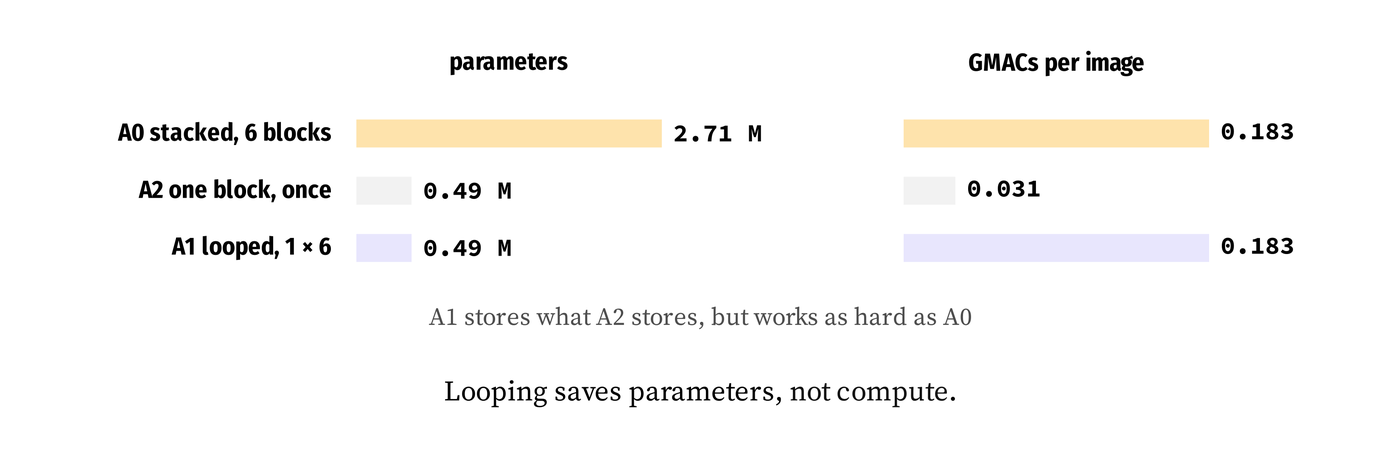

In [8]:
#@title Parameters and GMACs
def count_params(model):
    return sum(p.numel() for p in model.parameters())

def count_gmacs(model):
    model.eval()
    x = torch.randn(1, CHANNELS, IMG_SIZE, IMG_SIZE, device=device)
    with FlopCounterMode(display=False) as counter:
        model(x)
    return counter.get_total_flops() / 2 / 1e9

for name, model in [('A0 stacked, 6 blocks', StackedViT(DEPTH)),
                    ('A2 one block, run once', StackedViT(1)),
                    ('A1 looped, 1 block x 6', LoopedViT(DEPTH))]:
    model.to(device)
    print(f"{name:24s} params {count_params(model)/1e6:5.2f}M   GMACs {count_gmacs(model):.3f}")

A0 stacked, 6 blocks     params  2.71M   GMACs 0.183
A2 one block, run once   params  0.49M   GMACs 0.031


A1 looped, 1 block x 6   params  0.49M   GMACs 0.183


### What you should see

| Model | Params | GMACs |
| --- | ---: | ---: |
| A0 stacked, 6 blocks | about 2.71M | about 0.183 |
| A2 one block, run once | about 0.49M | about 0.031 |
| A1 looped, 1 block x 6 | about 0.49M | about 0.183 |

Read the rows in pairs:

- **A0 and A1** cost the same GMACs, but A1 stores about 5.5x fewer parameters (82% fewer). Both run six block passes per image. A smaller file is not a faster model. This is the same lesson the chapter's benchmark taught with EfficientFormer, and it is claim 1.
- **A1 and A2** store the same parameters, but A1 does six times the block work. If A1 is much more accurate than A2 after training, the extra accuracy comes from the looping itself.

The saving is about 5.5x rather than exactly 6x because the patch embedding, class token, positions, and head are not shared, and they are the same size in both models.

## 7. Three ways to train a looped model

The stacked models (A0, A2) are trained in the usual way, with cross-entropy on the final logits. For the looped model we compare three training objectives.

| Objective | Used by | Every loop learns from the label? | Early loops learn from the last loop? |
| --- | --- | :---: | :---: |
| `'last_loop'` | A4 | no, only the last loop | no |
| `'every_loop'` | A1 | yes | no |
| `'self_distill'` | A9 | yes | yes |

### Every loop (A1): addition 3

We compute the cross-entropy after *every* loop and combine the results. This is often called *deep supervision*. We give loop $t$ the weight $t$, so later loops count more:

$$
\mathcal{L}_{every} = \frac{\sum_{t=1}^{T} t \cdot \text{CE}(z_t, y)}{\sum_{t=1}^{T} t}
$$

Here $z_t$ is the logits after loop $t$, $y$ is the true label, and $T$ is the number of loops.

Why not a plain average? Our ablation sweep tried both. An equal weight on every loop makes the shared block work as hard for loop 1 as for loop 6, and it cost about 2 points of final accuracy. Weighting by $t$ recovered most of that while keeping the early loops usable. Self-distillation then lifts the early loops back up.

### Last loop only (A4)

Only the final loop's prediction is trained, as in a normal network. We expect the early loops to give poor answers, which would make early exit useless. A4 is the control that shows why addition 3 is needed.

### Self-distillation (A9): the last loop teaches the earlier loops

After each loop, the looped model makes a guess. Early loops are rough and later loops are better. For a picture of a **cat**, the guesses might look like this:

| | cat | dog | deer | truck |
| --- | ---: | ---: | ---: | ---: |
| Loop 1 | 35% | 30% | 25% | 10% |
| Loop 3 | 60% | 25% | 12% | 3% |
| **Loop 6 (last)** | **80%** | **15%** | **4%** | **1%** |
| Label | 100% | 0% | 0% | 0% |

The label tells loop 1 to jump straight to 100% cat, and treats "dog" and "truck" as equally wrong. Loop 6's answer is richer: it is a cat, it looks a bit like a dog, and it looks nothing like a truck. That is the **dark knowledge** from section 4.3.

Self-distillation gives loops 1 to 5 a second target: loop 6's answer. In DeiT a separate CNN is the teacher. Here the teacher is the same model's last loop, so no second network is needed:

```text
DeiT:               CNN teacher  --teaches-->  ViT student          (two networks)
Self-distillation:  loop 6       --teaches-->  loops 1, 2, 3, 4, 5  (one network)
```

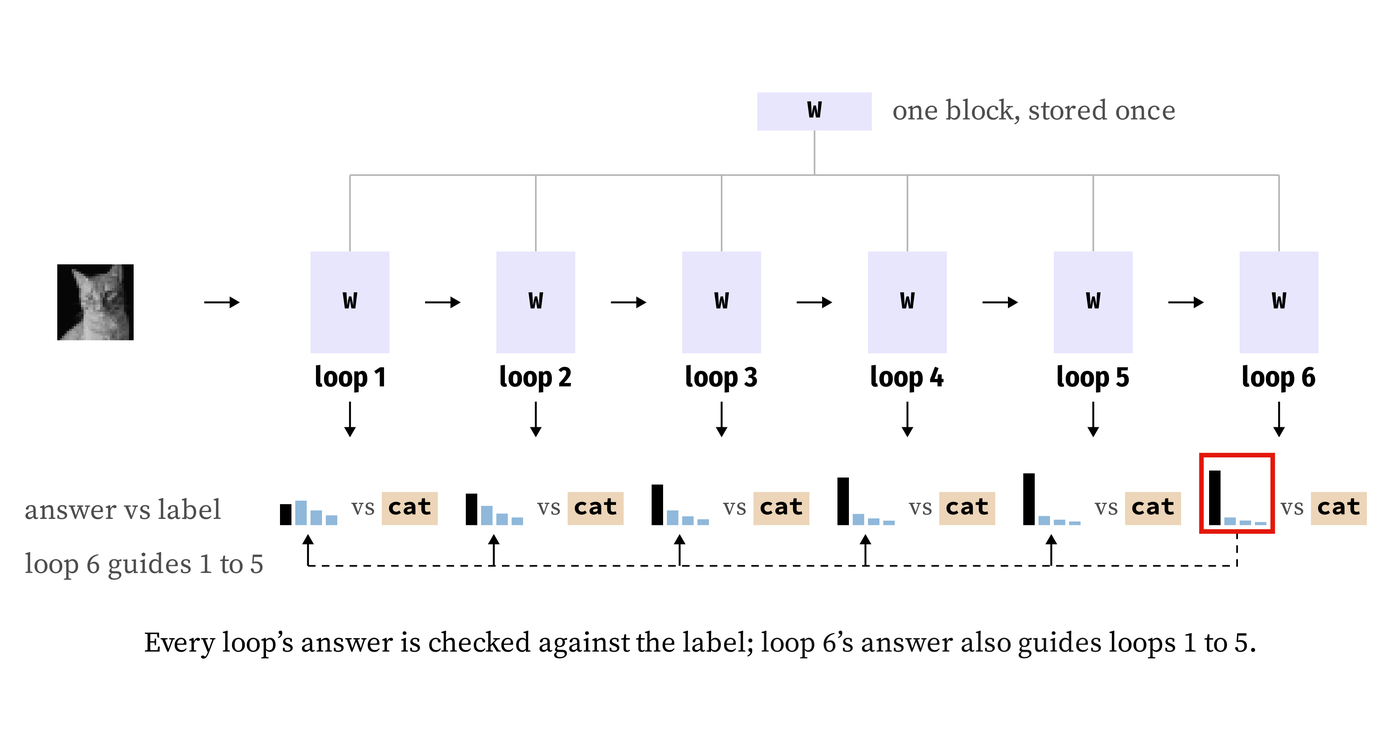

> **ANALOGY** You solve a hard problem in six drafts. The answer key says only "the answer is 42". Your sixth draft shows how you got there. Self-distillation checks every early draft against both the answer key and your own final draft, so the early drafts learn to head in the right direction sooner.

If the early loops learn to agree with the last loop sooner, they become confident about the right class earlier, and more images can stop early at the same accuracy. That is claim 3.

### Self-distillation on a toy example

Before writing the real loss, let's compute it by hand for the cat example. `F.kl_div` measures how different two probability lists are: zero when they match, larger when they disagree. Watch what happens as an early loop's guess moves closer to loop 6's.

**In pictures:** what the next cell does.

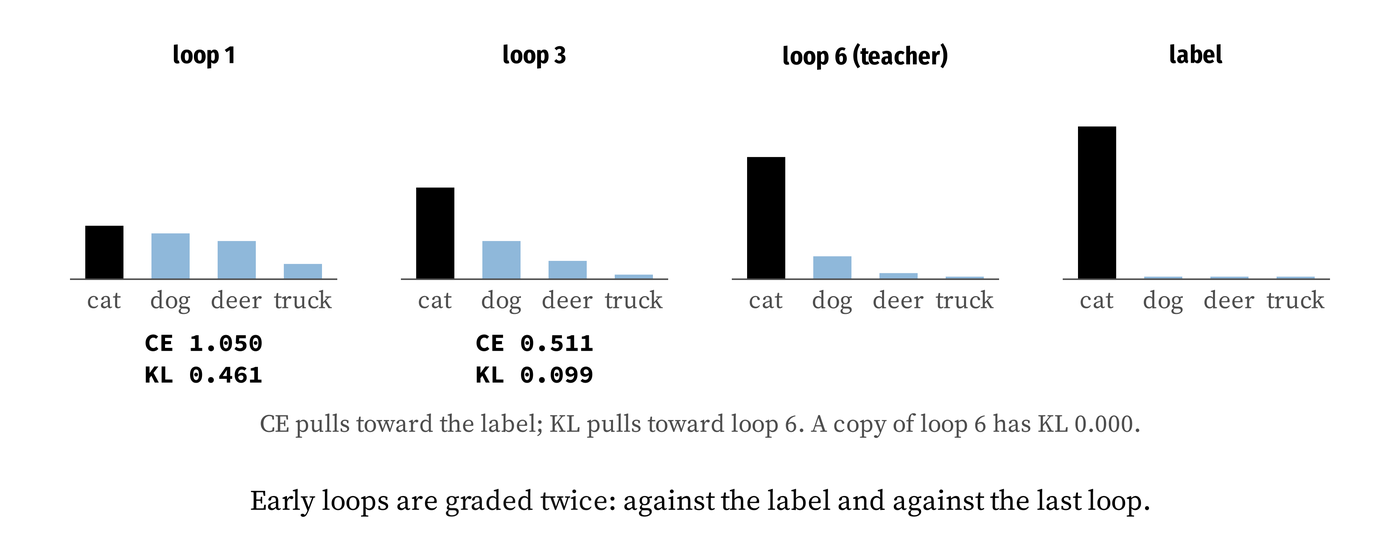

In [9]:
#@title Self-distillation on a toy example
classes = ['cat', 'dog', 'deer', 'truck']
label = torch.tensor([0])                                                  # the true class is "cat"
teacher = torch.tensor([[0.80, 0.15, 0.04, 0.01]])                         # loop 6's answer

for name, guess in [('loop 1', [0.35, 0.30, 0.25, 0.10]),
                    ('loop 3', [0.60, 0.25, 0.12, 0.03]),
                    ('copy of loop 6', [0.80, 0.15, 0.04, 0.01])]:
    logits = torch.tensor([guess]).log()                                   # treat log-probabilities as logits
    ce = F.cross_entropy(logits, label).item()
    kl = F.kl_div(logits.log_softmax(-1), teacher, reduction='batchmean').item()
    print(f"{name:15s} CE vs label {ce:.3f}   KL vs loop 6 {kl:.3f}")

loop 1          CE vs label 1.050   KL vs loop 6 0.461
loop 3          CE vs label 0.511   KL vs loop 6 0.099
copy of loop 6  CE vs label 0.223   KL vs loop 6 0.000


The cross-entropy term pulls every guess toward "100% cat". The KL term pulls an early guess toward loop 6's full answer, including the fact that "dog" deserves more probability than "truck". When an early loop copies loop 6 exactly, the KL term is zero.

### The real loss function

The real version adds two details from section 4.3:

- **Temperature.** Both distributions are divided by `KD_TEMPERATURE` before the softmax, which softens them so the small probabilities ("dog", "deer") carry more weight. The loss is multiplied by $\tau^2$ to keep its size comparable to the label loss.
- **The teacher does not learn from its students.** We call `.detach()` on the last loop's logits. The strong last loop pulls the early loops toward it, but is never pulled back toward their weaker guesses.

$$
\mathcal{L}_{self} = \mathcal{L}_{every} + \lambda \, \tau^2 \, \frac{1}{T-1} \sum_{t=1}^{T-1} \text{KL}\big(p_T^{\tau} \,\|\, p_t^{\tau}\big)
$$

Here $\tau$ is `KD_TEMPERATURE`, $\lambda$ is `KD_WEIGHT`, and $p_t^{\tau}$ is the softened probability list after loop $t$.

**In pictures:** what the next cell does.

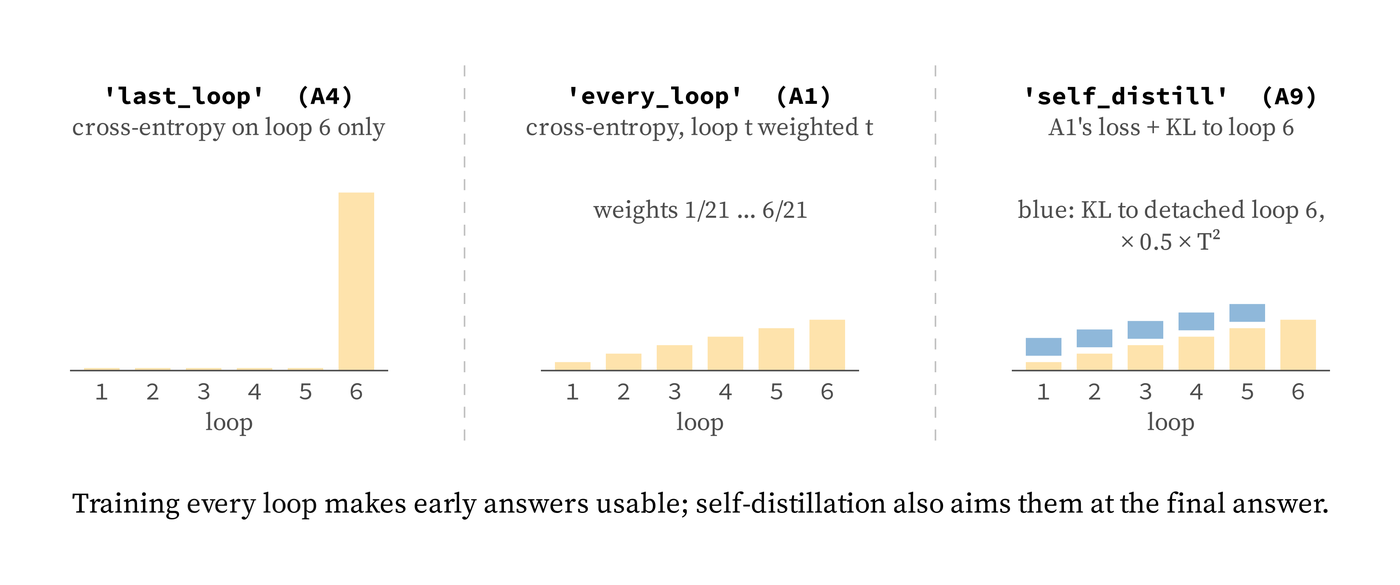

In [10]:
#@title Training objectives
def loss_fn(model, x, y, objective):
    if objective == 'final':
        return F.cross_entropy(model(x), y, label_smoothing=LABEL_SMOOTHING)
    logits = model.forward_all(x)                                          # [loops, B, CLASSES]
    ce = torch.stack([F.cross_entropy(z, y, label_smoothing=LABEL_SMOOTHING) for z in logits])
    if objective == 'last_loop':
        return ce[-1]                                                      #A
    w = torch.arange(1, len(ce) + 1, device=ce.device, dtype=ce.dtype)
    loss = (ce * w).sum() / w.sum()                                        #B
    if objective == 'self_distill':
        teacher = (logits[-1].detach().float() / KD_TEMPERATURE).softmax(-1)  #C
        kd = torch.stack([
            F.kl_div((z.float() / KD_TEMPERATURE).log_softmax(-1), teacher, reduction='batchmean')
            for z in logits[:-1]]).mean()                                  #D
        loss = loss + KD_WEIGHT * KD_TEMPERATURE ** 2 * kd
    return loss

Annotations: **#A** A4 trains only the last loop. **#B** A1 trains a label loss at every loop (addition 3), weighted 1, 2, ..., 6 so later loops count more. **#C** the last loop's softened probabilities are the teacher, frozen with `.detach()`. **#D** each earlier loop is pulled toward the teacher.

> **NOTE** Self-distillation adds almost no training cost: loop 6's answer is already computed in the normal forward pass. It adds nothing at inference, because the KL term exists only in the loss.

## 8. The training loop

Everything except the objective is identical for all five runs. One training step does the following:

1. Move a batch of images and labels to the device.
2. Compute the loss for this run's objective, in mixed precision on CUDA GPUs to save time and memory.
3. Backpropagate, clip the gradient norm to 1.0 to avoid rare large updates, and take an AdamW step.
4. Advance the one-cycle learning-rate schedule, which warms up for the first 10% of training and then decays.

After each epoch we record validation accuracy at full depth and keep a copy of the weights from the best epoch.

`run_experiment` wraps training with two conveniences:

- it resets the random seed, so every run starts from the same initial conditions;
- it saves each finished run to `CHECKPOINT_DIR`, and loads that file instead of retraining if it already exists.

> **TIP** To retrain a run from scratch, delete its file in `./checkpoints`, for example `cifar100_A1_looped.pt`.

In [11]:
#@title Training loop
@torch.no_grad()
def accuracy(model, loader):
    model.eval()
    correct = total = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        correct += (model(x).argmax(1) == y).sum().item()
        total += y.size(0)
    return 100 * correct / total

def train_model(model, name, objective):
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=EPOCHS * len(train_dl), pct_start=0.1)
    use_amp = device == 'cuda'
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    history, best_acc, best_state = [], 0.0, None
    start = time.time()
    for epoch in range(EPOCHS):
        model.train()
        for x, y in train_dl:
            x, y = x.to(device), y.to(device)
            with torch.autocast('cuda', dtype=torch.float16, enabled=use_amp):
                loss = loss_fn(model, x, y, objective)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            sched.step()
        val_acc = accuracy(model, val_dl)
        history.append(val_acc)
        if val_acc > best_acc:
            best_acc = val_acc
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}  #A
        print(f"{name} epoch {epoch+1:2d}/{EPOCHS}  loss {loss.item():.3f}  val {val_acc:.2f}%  ({time.time()-start:.0f}s)")
    model.load_state_dict(best_state)
    return history, (time.time() - start) / 60

def run_experiment(key, make_model, objective):
    torch.manual_seed(SEED)                                                #B
    model = make_model().to(device)
    path = os.path.join(CHECKPOINT_DIR, f"{DATASET}_{key}.pt")
    if os.path.exists(path):                                               #C
        saved = torch.load(path, map_location=device)
        model.load_state_dict(saved['state'])
        print(f"{key}: loaded from {path}")
        return model, saved['history'], saved['minutes']
    history, minutes = train_model(model, key, objective)
    os.makedirs(CHECKPOINT_DIR, exist_ok=True)
    torch.save({'state': model.state_dict(), 'history': history, 'minutes': minutes}, path)
    return model, history, minutes

Annotations: **#A** keep a copy of the weights from the epoch with the best validation accuracy. **#B** every run starts from the same seed, so the five runs differ only in what we chose to change. **#C** a finished run is loaded instead of retrained.

## 9. Run the five experiments

Each entry names a model and an objective. This is the longest cell in the notebook: on a T4 it took 80 minutes in total.

| Key | Model | Objective |
| --- | --- | --- |
| `A0_stacked` | `StackedViT(6)` | `'final'` |
| `A2_one_block` | `StackedViT(1)` | `'final'` |
| `A1_looped` | `LoopedViT(6)` | `'every_loop'` |
| `A4_last_loop` | `LoopedViT(6)` | `'last_loop'` |
| `A9_self_distill` | `LoopedViT(6)` | `'self_distill'` |

### What you should see while it runs

- The loss falls quickly in the first few epochs, then slowly.
- Validation accuracy keeps rising for most of training, then levels off as the learning rate decays.
- The looped runs take about as long per epoch as the stacked run. Same GMACs, same time.
- On a 2-core machine every run takes about the same time, because preparing the images is the bottleneck.

Our run on a T4 ended with these validation accuracies (last loop, best epoch):

| Run | Val top-1 | Minutes |
| --- | ---: | ---: |
| A0 stacked | 58.2% | 16.2 |
| A2 one block | 32.0% | 15.6 |
| A1 looped, every loop | 53.7% | 16.2 |
| A4 looped, last loop only | 56.3% | 16.2 |
| A9 looped + self-distillation | 53.0% | 16.1 |

> **NOTE** Your exact accuracies will differ from anyone else's: GPU type, PyTorch version, and random data-loader order all change the last digits. The comparisons between runs are what matter.

> **WARNING** Without TrivialAugment and random erasing, A0's training loss keeps falling while its validation accuracy stalls near 53%: it memorizes the training images. This is **overfitting**, and it is common for ViTs trained from scratch on small datasets. Try it: remove the two augmentation lines, retrain A0, and watch the gap open.

**In pictures:** what the next cell does.

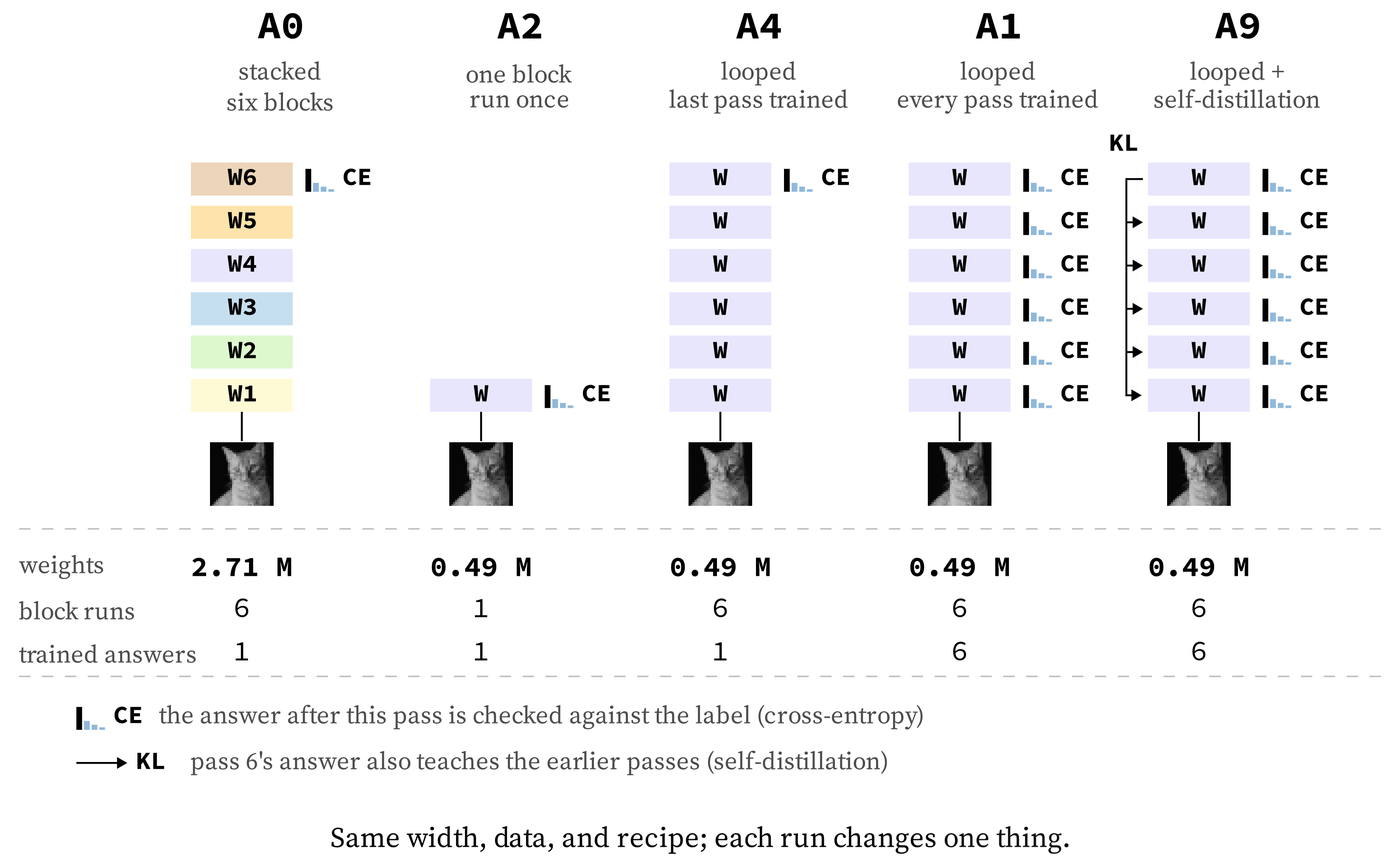

A0_stacked epoch  1/60  loss 4.312  val 8.92%  (17s)


A0_stacked epoch  2/60  loss 4.058  val 12.68%  (33s)


A0_stacked epoch  3/60  loss 3.891  val 16.68%  (49s)


A0_stacked epoch  4/60  loss 3.851  val 19.04%  (66s)


A0_stacked epoch  5/60  loss 3.792  val 21.70%  (83s)


A0_stacked epoch  6/60  loss 3.849  val 23.16%  (99s)


... (290 outputs left out)

A9_self_distill epoch 57/60  loss 2.621  val 52.80%  (920s)


A9_self_distill epoch 58/60  loss 2.681  val 52.86%  (936s)


A9_self_distill epoch 59/60  loss 2.639  val 52.92%  (952s)


A9_self_distill epoch 60/60  loss 2.793  val 52.86%  (968s)


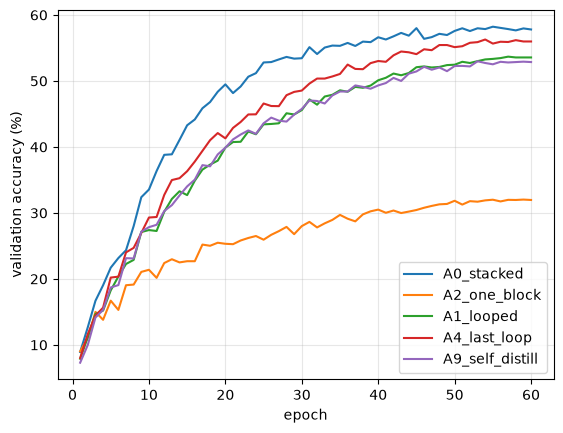

training minutes: {'A0_stacked': 16.2, 'A2_one_block': 15.6, 'A1_looped': 16.2, 'A4_last_loop': 16.2, 'A9_self_distill': 16.1}  total 80.4


In [12]:
#@title Train all runs
EXPERIMENTS = {
    'A0_stacked':      (lambda: StackedViT(DEPTH), 'final'),
    'A2_one_block':    (lambda: StackedViT(1),     'final'),
    'A1_looped':       (lambda: LoopedViT(DEPTH),  'every_loop'),
    'A4_last_loop':    (lambda: LoopedViT(DEPTH),  'last_loop'),
    'A9_self_distill': (lambda: LoopedViT(DEPTH),  'self_distill'),
}

models, histories, minutes = {}, {}, {}
for key, (make_model, objective) in EXPERIMENTS.items():
    models[key], histories[key], minutes[key] = run_experiment(key, make_model, objective)

for key in EXPERIMENTS:
    plt.plot(range(1, len(histories[key]) + 1), histories[key], label=key)
plt.xlabel('epoch'); plt.ylabel('validation accuracy (%)'); plt.legend(); plt.grid(alpha=0.3)
plt.show()
print('training minutes:', {k: round(v, 1) for k, v in minutes.items()}, ' total', round(sum(minutes.values()), 1))

## 10. Accuracy after every loop

The looped models produce a prediction after every loop, so we can read off their accuracy at 1, 2, ... loops without retraining. We also run them for **twice as many loops** as they were trained with, to see whether "thinking longer" at test time helps.

`collect_loop_probs` runs every image through all loops once and stores the softmax probabilities from each loop, in a tensor of shape `[loops, images, classes]`. The rest of the notebook reuses those stored probabilities, so changing a threshold later costs no extra model computation.

The plot shows one line per looped model, plus two horizontal reference lines for the stacked models, which only have one answer each.

**In pictures:** what the next cell does.

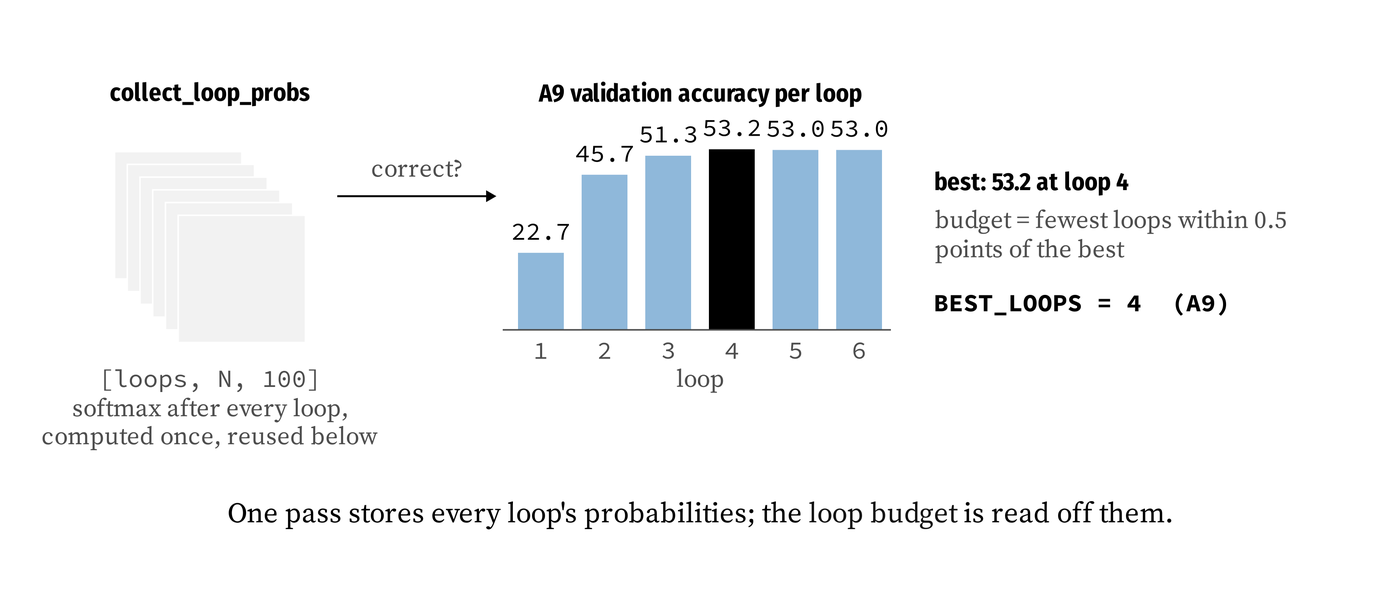

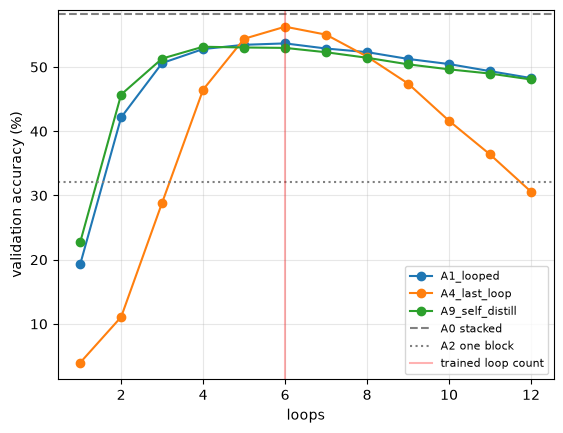

loops:                  1      2      3      4      5      6      7      8      9     10     11     12
A1_looped            19.3   42.2   50.6   52.8   53.5   53.7   52.9   52.3   51.3   50.5   49.4   48.3
A4_last_loop          4.0   11.1   28.9   46.5   54.4   56.3   55.0   51.6   47.4   41.6   36.4   30.6
A9_self_distill      22.7   45.7   51.3   53.2   53.0   53.0   52.3   51.4   50.4   49.6   49.0   48.1
A0 stacked 58.2   A2 one block 32.0
fewest loops within 0.5 pt of the best loop: {'A1_looped': 5, 'A4_last_loop': 6, 'A9_self_distill': 4}


In [13]:
#@title Accuracy at every loop count
LOOPED = ['A1_looped', 'A4_last_loop', 'A9_self_distill']

@torch.no_grad()
def collect_loop_probs(model, loader, loops):
    model.eval()
    probs, labels = [], []
    for x, y in loader:
        probs.append(model.forward_all(x.to(device), loops).softmax(-1).cpu())
        labels.append(y)
    return torch.cat(probs, dim=1), torch.cat(labels)                     # [loops, N, CLASSES], [N]

max_loops = 2 * DEPTH
val_probs, val_labels, loop_acc, BEST_LOOPS = {}, None, {}, {}
for key in LOOPED:
    val_probs[key], val_labels = collect_loop_probs(models[key], val_dl, max_loops)
    loop_acc[key] = [(val_probs[key][t].argmax(-1) == val_labels).float().mean().item() * 100 for t in range(max_loops)]
    trained = loop_acc[key][:DEPTH]
    BEST_LOOPS[key] = min(t + 1 for t in range(DEPTH) if trained[t] >= max(trained) - 0.5)   #A
    plt.plot(range(1, max_loops + 1), loop_acc[key], marker='o', label=key)

val_acc = {key: accuracy(models[key], val_dl) for key in ['A0_stacked', 'A2_one_block']}
plt.axhline(val_acc['A0_stacked'], color='gray', linestyle='--', label='A0 stacked')
plt.axhline(val_acc['A2_one_block'], color='gray', linestyle=':', label='A2 one block')
plt.axvline(DEPTH, color='red', alpha=0.3, label='trained loop count')
plt.xlabel('loops'); plt.ylabel('validation accuracy (%)'); plt.legend(fontsize=8); plt.grid(alpha=0.3)
plt.show()

print('loops:            ' + ''.join(f'{t:>7d}' for t in range(1, max_loops + 1)))
for key in LOOPED:
    print(f'{key:17s} ' + ''.join(f'{a:7.1f}' for a in loop_acc[key]))
print('A0 stacked', round(val_acc['A0_stacked'], 1), '  A2 one block', round(val_acc['A2_one_block'], 1))
print('fewest loops within 0.5 pt of the best loop:', BEST_LOOPS)

Annotation: **#A** the fewest loops (out of the trained six) whose validation accuracy is within 0.5 percentage points of the best loop. We call it `BEST_LOOPS` and use it as the loop budget in sections 11 and 12.

### Things to look for

- **A1 against the two gray lines.** How close does one looped block get to six stacked blocks (A0), and how far above the one-block model (A2) does it climb? In our run A1 reached 53.7% at loop 6, far above A2's 32.0% and about 4.5 points below A0's 58.2%.
- **A4's early loops.** Trained only at the end, its early-loop predictions are almost useless: 4.0% after one loop, 11.1% after two. A1 already reaches 19.3% and 42.2%. That is why addition 3 exists.
- **A9 against A1 at loops 1 to 3.** If self-distillation works, A9's early loops are more accurate. In our run they were: 22.7% vs 19.3% at loop 1, 45.7% vs 42.2% at loop 2, and 51.3% vs 50.6% at loop 3.
- **The best loop is not always the last.** A9 is already at its best by loop 4 and A1 by loop 5 or 6; after that, extra loops do not help, and beyond loop 6 they hurt. Researchers call this **overthinking**. So we use `BEST_LOOPS` as the loop budget from now on: 5 for A1, 4 for A9, and 6 for A4.
- **Loops 7 to 12.** The models never practised these loops, and accuracy keeps falling. A4 collapses fastest (30.6% at loop 12), while A1 and A9 decline gently. Research on looped networks found that "thinking longer" pays off mainly on algorithmic problems such as mazes, and only with special training tricks such as recall (see "Try this"). On photographs, the reliable win is the other direction: stopping *earlier*.

<details>
<summary><b>Check your understanding:</b> A2 and A1 have the same parameters. If A1 is clearly more accurate, what does that tell you?</summary>

The accuracy gap comes from compute, not from storage. Both models own one block of weights, but A1 applies it six times. Looping lets a small set of weights do more work per image.
</details>

## 11. Early exit: stop when the model is confident

Here is the rule. After each loop, look at the highest softmax probability, the model's **confidence**. If it is at least a threshold $\tau$, stop and answer. Otherwise run another loop. After the final trained loop, always answer.

```text
tau = 0.9
loop 1: top class "cat", confidence 0.42  < 0.9   -> keep looping
loop 2: top class "cat", confidence 0.71  < 0.9   -> keep looping
loop 3: top class "cat", confidence 0.93  >= 0.9  -> stop and answer "cat"
        3 of 6 loops used: half the block compute for this image
```

| Threshold | Behaviour | Effect |
| --- | --- | --- |
| high, near 1.0 | stop only when very sure | more loops, close to full accuracy |
| low, near 0.1 | stop at the first hint | fewer loops, lower accuracy |

Sweeping $\tau$ traces an **accuracy-versus-compute curve**. We measure compute as the average number of loops per image, since every loop costs one block pass.

`simulate_exit` applies the rule to the stored probabilities from section 10. It needs no extra model calls, so the whole sweep takes a fraction of a second.

**In pictures:** what the next cell does.

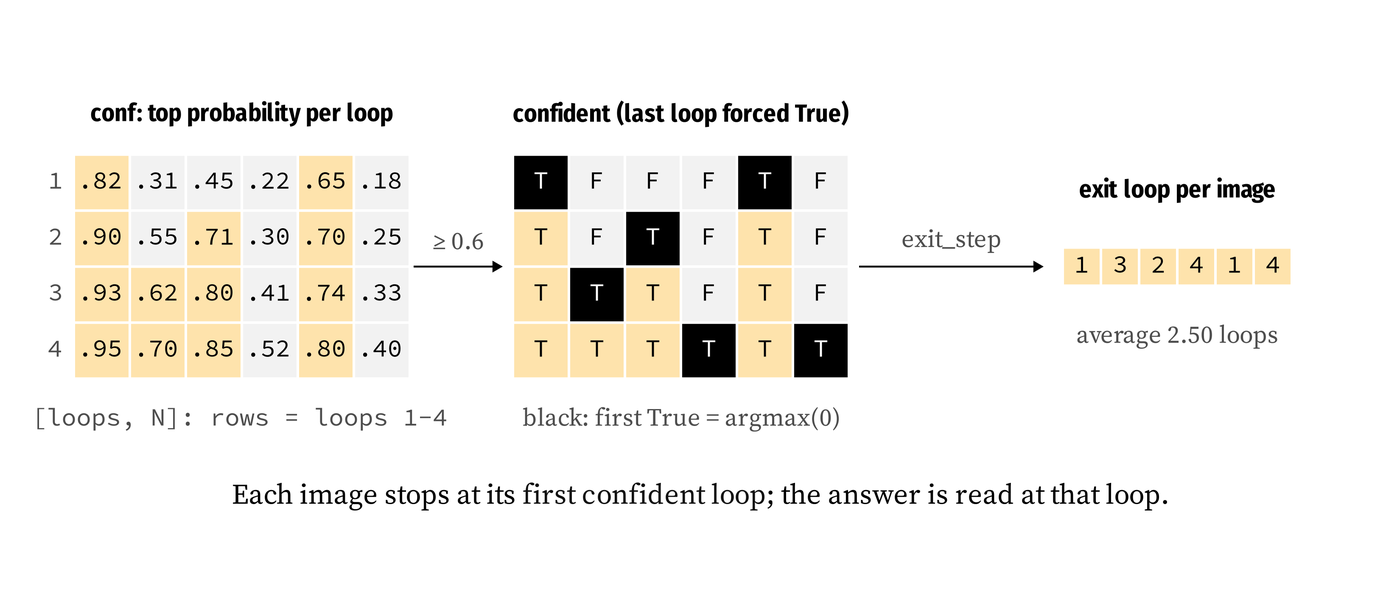

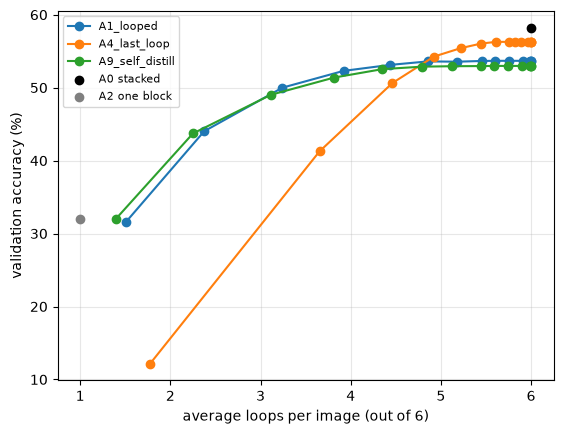

In [14]:
#@title Simulate early exit from stored probabilities
def simulate_exit(probs, labels, threshold, loops=DEPTH):
    conf, pred = probs[:loops].max(-1)                                     # [loops, N]
    confident = conf >= threshold
    confident[-1] = True                                                   #A
    exit_step = confident.float().argmax(0)                                #B
    final_pred = pred.gather(0, exit_step[None]).squeeze(0)
    acc = (final_pred == labels).float().mean().item() * 100
    return acc, (exit_step + 1).float().mean().item(), exit_step + 1

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95, 0.98, 0.99, 1.01]
sweeps = {key: [simulate_exit(val_probs[key], val_labels, t)[:2] for t in thresholds] for key in LOOPED}

for key in LOOPED:
    plt.plot([s[1] for s in sweeps[key]], [s[0] for s in sweeps[key]], marker='o', label=key)
plt.scatter([DEPTH], [val_acc['A0_stacked']], color='black', zorder=3, label='A0 stacked')
plt.scatter([1], [val_acc['A2_one_block']], color='gray', zorder=3, label='A2 one block')
plt.xlabel(f'average loops per image (out of {DEPTH})'); plt.ylabel('validation accuracy (%)')
plt.legend(fontsize=8); plt.grid(alpha=0.3)
plt.show()

Annotations: **#A** every image must leave by the last loop. **#B** `argmax` over a boolean column returns the *first* loop where the model was confident.

### How to read the plot

- **Up** is more accurate. **Left** is cheaper.
- Each dot on a line is one threshold. The rightmost dot of each line is "always use all 6 loops".
- A9's line above or to the left of A1's means self-distillation buys the same accuracy for fewer loops.
- A4's line should fall steeply as it moves left, because its early answers are poor.
- The black dot is A0, which always pays for 6 blocks. The gray dot is A2, which always pays for 1.

### Choose the threshold on validation data

For each looped model we now combine two ideas:

1. **A loop budget.** No image may use more than `BEST_LOOPS` loops, since later loops only overthink.
2. **A threshold.** Within that budget, we pick the threshold that uses the fewest loops on average while staying within 0.5 percentage points of the model's best validation accuracy.

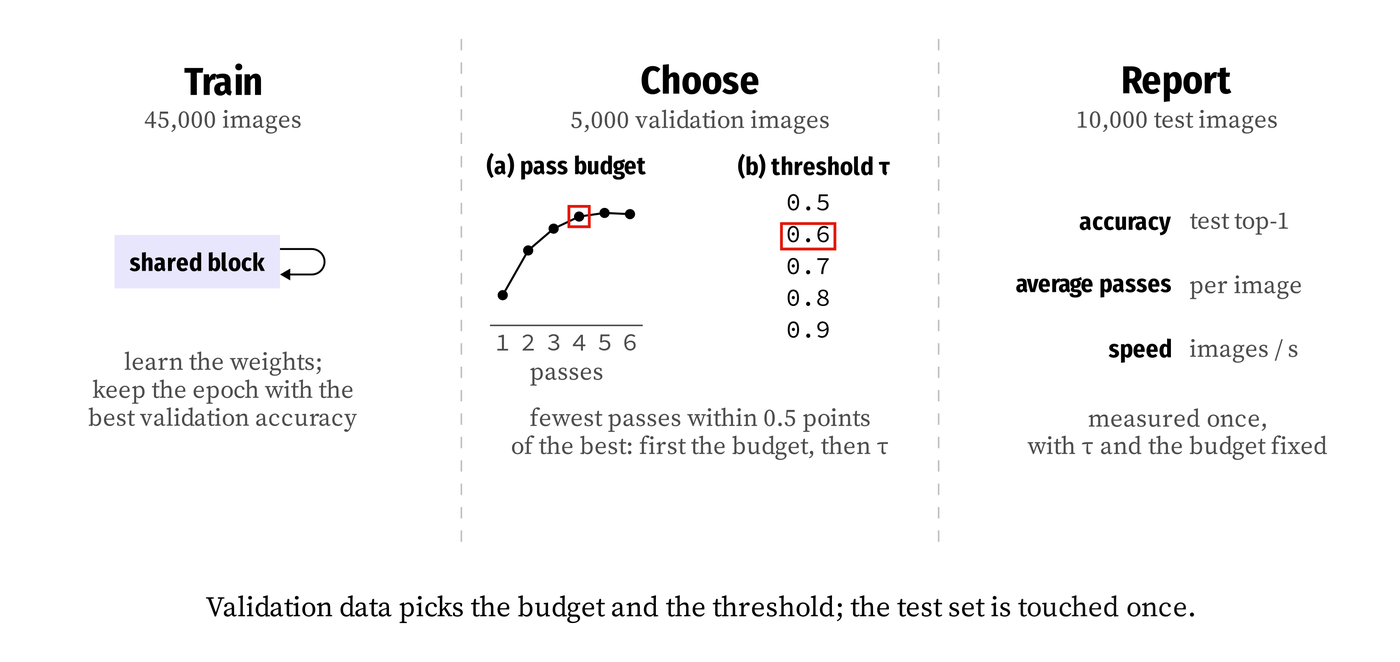

> **WARNING** Both choices use validation data only. Choosing them on the test set would make the test score look better than the model really is.

In [15]:
#@title Pick tau for each looped model
TAU = {}
for key in LOOPED:
    cap, target = BEST_LOOPS[key], max(loop_acc[key][:DEPTH]) - 0.5
    candidates = []
    for t in thresholds:
        acc, avg, _ = simulate_exit(val_probs[key], val_labels, t, loops=cap)        #A
        if acc >= target:
            candidates.append((avg, t))
    TAU[key] = min(candidates)[1]                                                    #B
print('loop budget:', BEST_LOOPS)
print('chosen tau: ', TAU)

loop budget: {'A1_looped': 5, 'A4_last_loop': 6, 'A9_self_distill': 4}
chosen tau:  {'A1_looped': 0.6, 'A4_last_loop': 0.6, 'A9_self_distill': 0.6}


Annotations: **#A** simulate the exit rule with the loop budget as the last loop. **#B** among thresholds that keep accuracy within 0.5 points of the best loop, keep the one with the fewest average loops. A threshold of 1.01 can never fire, which gives the plain budget, so there is always at least one candidate.

## 12. Real early exit and real speed

The simulation above computed every loop for every image and then pretended to stop. To save real time, the model must actually stop working on finished images. `predict_with_exit` does that. After each loop it removes the confident images from the batch, so later loops run on fewer and fewer images:

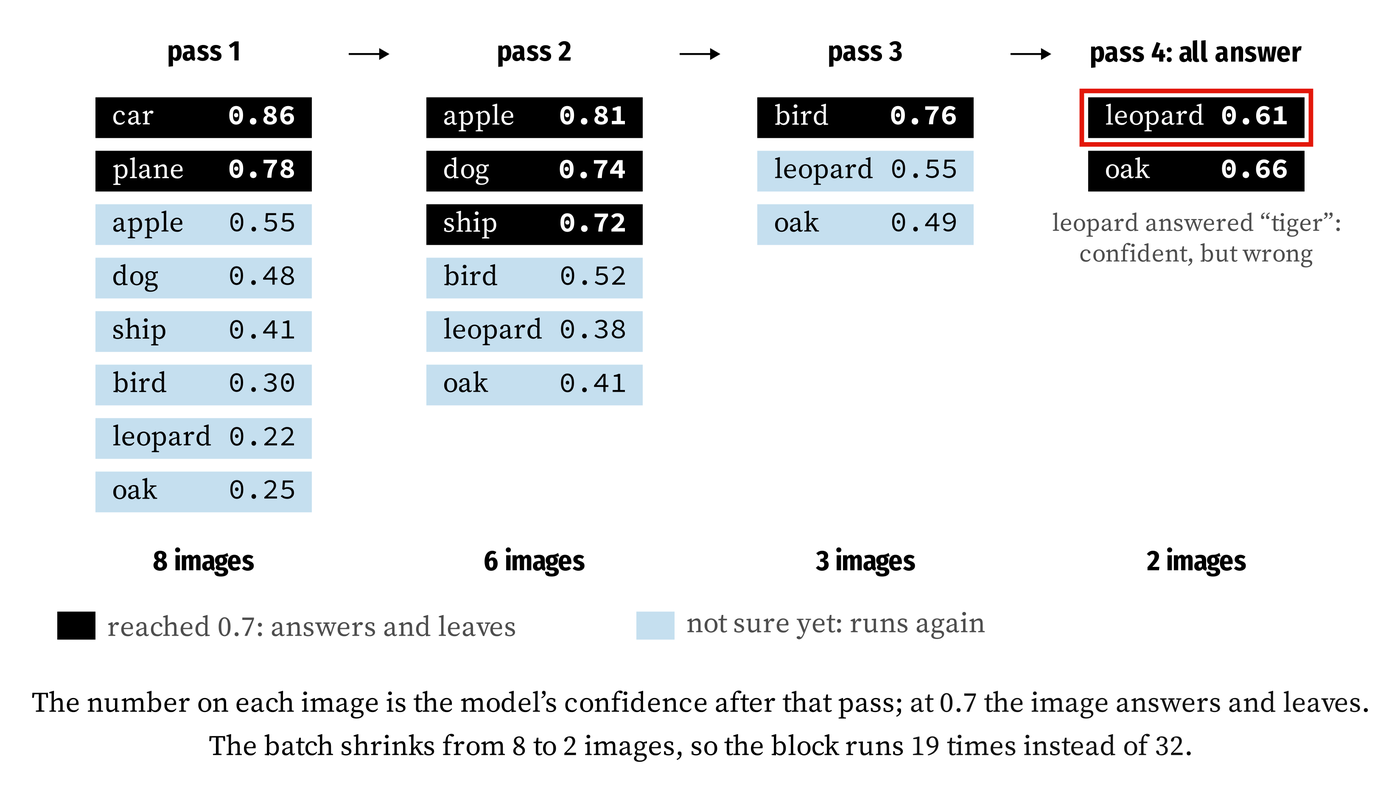

**In pictures:** what the next cell does.

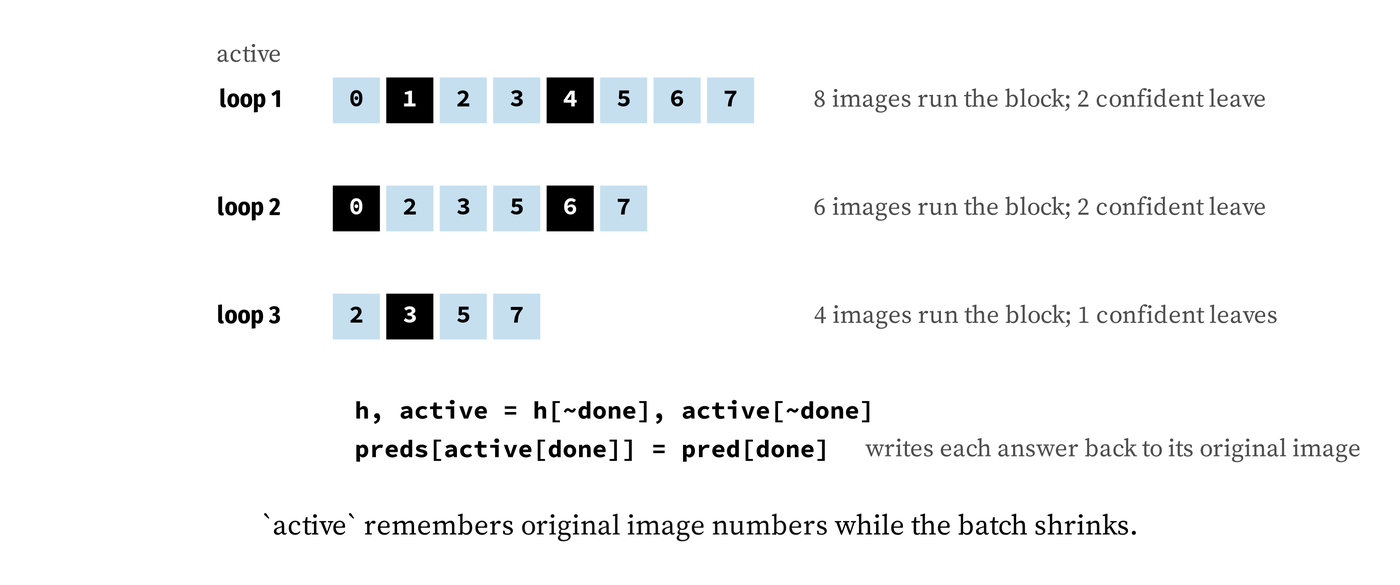

In [16]:
#@title Early exit for real
@torch.no_grad()
def predict_with_exit(model, x, threshold, loops=DEPTH):
    h = model.embed(x)
    preds = torch.empty(x.size(0), dtype=torch.long, device=x.device)
    exit_at = torch.empty(x.size(0), dtype=torch.long, device=x.device)
    active = torch.arange(x.size(0), device=x.device)                      #A
    for t in range(loops):
        h = model.block(h + model.step_embed(t))
        conf, pred = model.classify(h).softmax(-1).max(-1)
        done = conf >= threshold if t < loops - 1 else torch.ones_like(conf, dtype=torch.bool)
        preds[active[done]] = pred[done]
        exit_at[active[done]] = t + 1
        h, active = h[~done], active[~done]                                #B
        if active.numel() == 0:
            break
    return preds, exit_at

Annotations: **#A** `active` remembers which original images are still in the batch. **#B** drop the finished images, so the next loop does less work.

### Measuring on the test set

Now we time every option on the same device. The timing function runs a few warm-up batches first and synchronizes the GPU before reading the clock, so we measure finished work rather than queued work. This is the first and only time we use the test set.

For each looped model we report up to three rows: all six loops; a **fixed** loop budget, where every image runs exactly `BEST_LOOPS` loops; and early exit within that budget, with the threshold chosen on validation.

**In pictures:** what the next cell does.

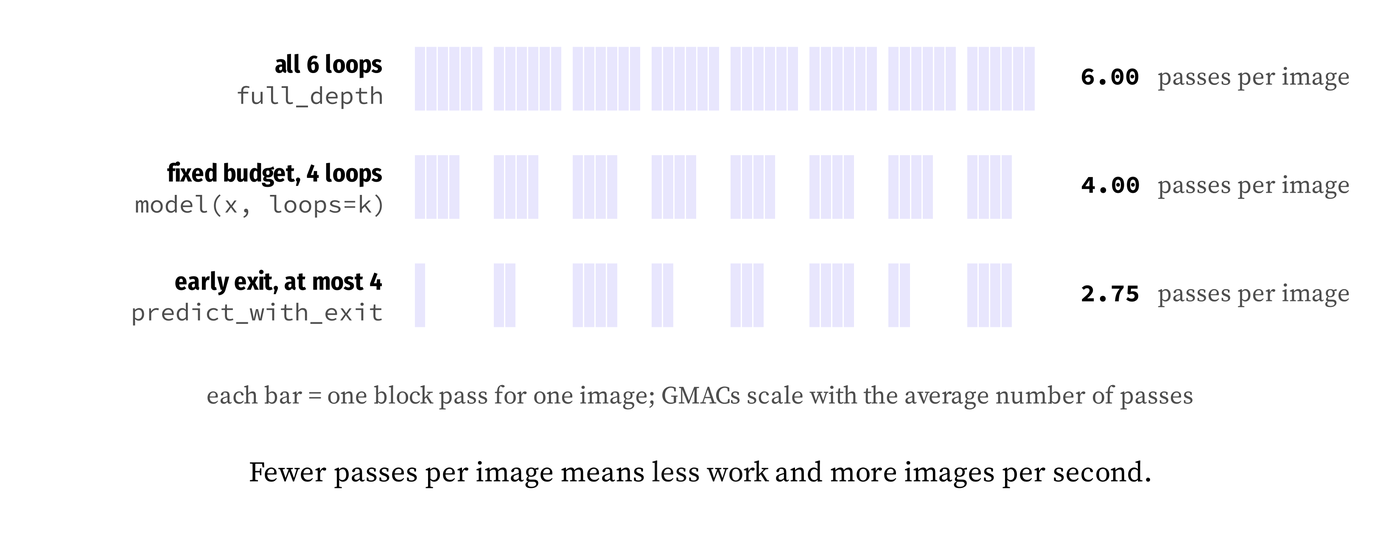

In [17]:
#@title Test accuracy and throughput
def sync():
    if device == 'cuda':
        torch.cuda.synchronize()
    elif device == 'mps':
        torch.mps.synchronize()

@torch.no_grad()
def evaluate(predict, loader, warmup=3):
    batches = [(x.to(device), y.to(device)) for x, y in loader]
    for x, _ in batches[:warmup]:
        predict(x)
    sync(); start = time.perf_counter()
    correct, loops_used = 0, []
    for x, y in batches:
        pred, loops = predict(x)
        correct += (pred == y).sum().item()
        loops_used.append(loops.float())
    sync(); seconds = time.perf_counter() - start
    n = sum(y.size(0) for _, y in batches)
    return 100 * correct / n, n / seconds, torch.cat(loops_used).mean().item()

def full_depth(model, depth):
    return lambda x: (model(x).argmax(1), torch.full((x.size(0),), depth))

for model in models.values():
    model.eval()
rows = [('A0 stacked', 'A0_stacked', evaluate(full_depth(models['A0_stacked'], DEPTH), test_dl)),
        ('A2 one block', 'A2_one_block', evaluate(full_depth(models['A2_one_block'], 1), test_dl))]
for key in LOOPED:
    k = BEST_LOOPS[key]
    rows.append((f'{key}, all {DEPTH} loops', key, evaluate(full_depth(models[key], DEPTH), test_dl)))
    if k < DEPTH:
        rows.append((f'{key}, fixed {k} loops', key,
                     evaluate(lambda x, m=models[key], k=k: (m(x, loops=k).argmax(1), torch.full((x.size(0),), k)), test_dl)))
    rows.append((f'{key}, exit tau={TAU[key]} max {k}', key,
                 evaluate(lambda x, m=models[key], t=TAU[key], k=k: predict_with_exit(m, x, t, loops=k), test_dl)))

gmacs = {key: count_gmacs(models[key]) for key in models}
print(f"{'Model':36s} {'Params':>8s} {'GMACs':>7s} {'Avg loops':>10s} {'Test top-1':>11s} {'Images/s':>9s}")
for name, key, (acc, ips, avg) in rows:
    loops_run = 1 if key == 'A2_one_block' else DEPTH
    print(f"{name:36s} {count_params(models[key])/1e6:7.2f}M {gmacs[key] * avg / loops_run:7.3f} "
          f"{avg:10.2f} {acc:10.2f}% {ips:9.0f}")

Model                                  Params   GMACs  Avg loops  Test top-1  Images/s
A0 stacked                              2.71M   0.183       6.00      58.88%      5892
A2 one block                            0.49M   0.031       1.00      31.66%     34180
A1_looped, all 6 loops                  0.49M   0.183       6.00      53.14%      5920
A1_looped, fixed 5 loops                0.49M   0.152       5.00      53.46%      7083
A1_looped, exit tau=0.6 max 5           0.49M   0.129       4.22      53.34%      7939
A4_last_loop, all 6 loops               0.49M   0.183       6.00      55.27%      5964
A4_last_loop, exit tau=0.6 max 6        0.49M   0.167       5.46      55.05%      6270
A9_self_distill, all 6 loops            0.49M   0.183       6.00      52.87%      5926
A9_self_distill, fixed 4 loops          0.49M   0.122       4.00      52.96%      8814
A9_self_distill, exit tau=0.6 max 4     0.49M   0.107       3.50      52.67%      9604


### Reading the results table

Read the table one column at a time:

| Column | What to look for |
| --- | --- |
| **Params** | Every looped model stores about the same weights as A2, a fraction of A0's |
| **GMACs** | At full depth the looped models match A0. Only the exit rows go down. (For exit rows this is the full-depth count scaled by the average number of loops) |
| **Avg loops** | If self-distillation works, A9's rows use fewer loops than A1's |
| **Test top-1** | One seed on a small model: treat differences below about one percentage point as noise |
| **Images/s** | Early exit should raise throughput, though by less than the loop count suggests |

Here is what our T4 run printed for the looped models:

| Row | GMACs | Avg loops | Test top-1 | Images/s |
| --- | ---: | ---: | ---: | ---: |
| A1, all 6 loops | 0.183 | 6.00 | 53.14% | 5,920 |
| A1, fixed 5 loops | 0.152 | 5.00 | 53.46% | 7,083 |
| A1, exit tau=0.6, max 5 | 0.129 | 4.22 | 53.34% | 7,939 |
| A9, all 6 loops | 0.183 | 6.00 | 52.87% | 5,926 |
| A9, fixed 4 loops | 0.122 | 4.00 | 52.96% | 8,814 |
| A9, exit tau=0.6, max 4 | 0.107 | 3.50 | 52.67% | 9,604 |

Three lessons stand out:

- **Fewer loops lose almost nothing.** A1 with 5 loops and A9 with 4 loops match their own 6-loop answers while doing a sixth to a third less work.
- **Self-distillation earns its place in the early loops.** A9 reaches its best accuracy one loop sooner than A1, so its loop budget is 4 instead of 5. Over five seeds, A9 with early exit needed 3.7 block passes per image against A1's 4.1, for the same accuracy.
- **Most of the saving comes from the budget, not the threshold.** Per-image early exit trims a further 10-15% of the loops for a fraction of a point. The confidence rule would do more with a stronger model: at around 53% accuracy, most CIFAR-100 images never become confident enough to leave early.

> **NOTE** On a GPU, early exit speeds things up less than the loop count suggests, because a half-empty batch does not run twice as fast and removing finished images has its own cost. The saving is larger on a CPU, or when the test batch size is larger. Try `batch_size=1024` in `test_dl` and compare.

## 13. Which images are easy?

The exit loop is a free "difficulty score" for every image. Images that leave after one loop are typically clean, centered, and typical of their class. Images that need every loop are often small, cluttered, unusual, or similar to another class, and they are also where most mistakes happen.

The cell below shows three views:

1. a histogram of where test images stop, for A1 and A9 side by side;
2. accuracy for each exit loop, for A9;
3. a gallery of images that exit at loop 1 and images that use the whole loop budget.

**In pictures:** what the next cell does.

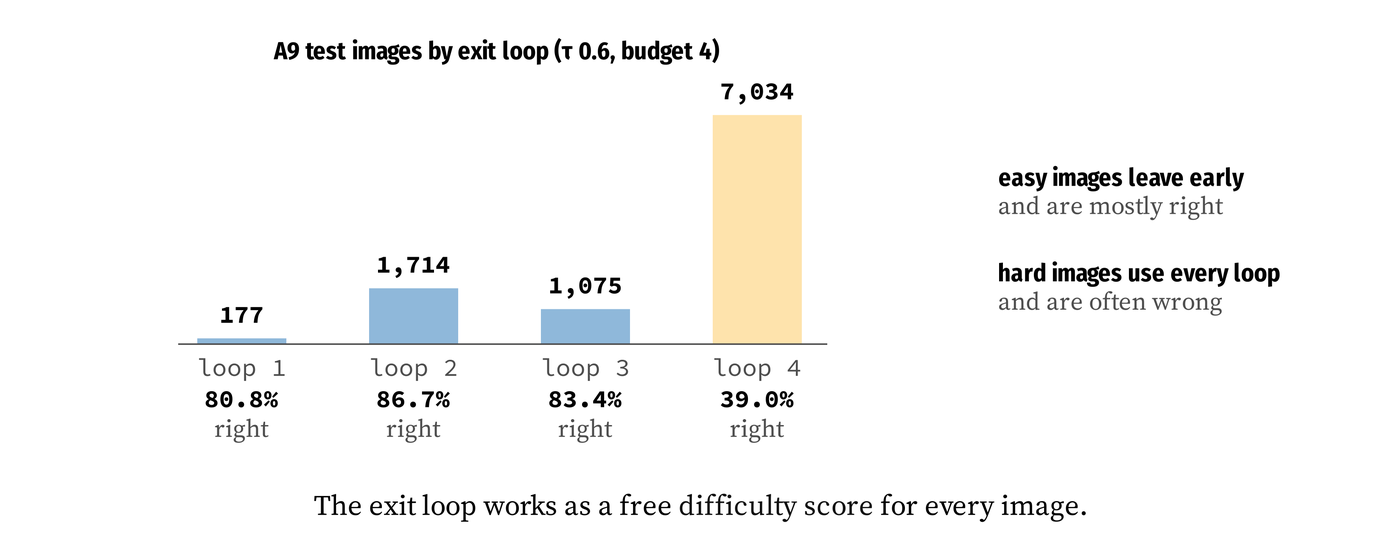

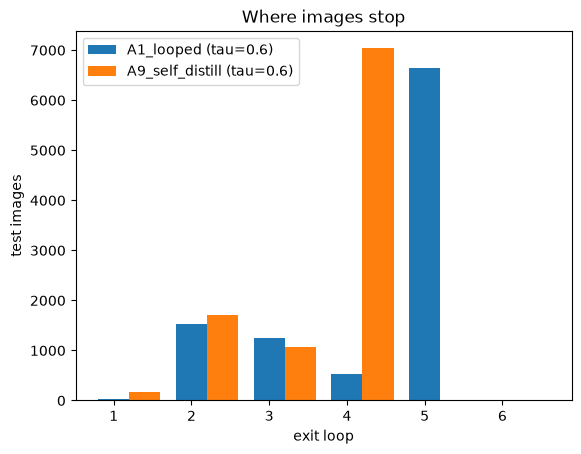

A9_self_distill exit at loop 1:   177 images, accuracy  80.8%
A9_self_distill exit at loop 2:  1714 images, accuracy  86.7%
A9_self_distill exit at loop 3:  1075 images, accuracy  83.4%
A9_self_distill exit at loop 4:  7034 images, accuracy  39.0%


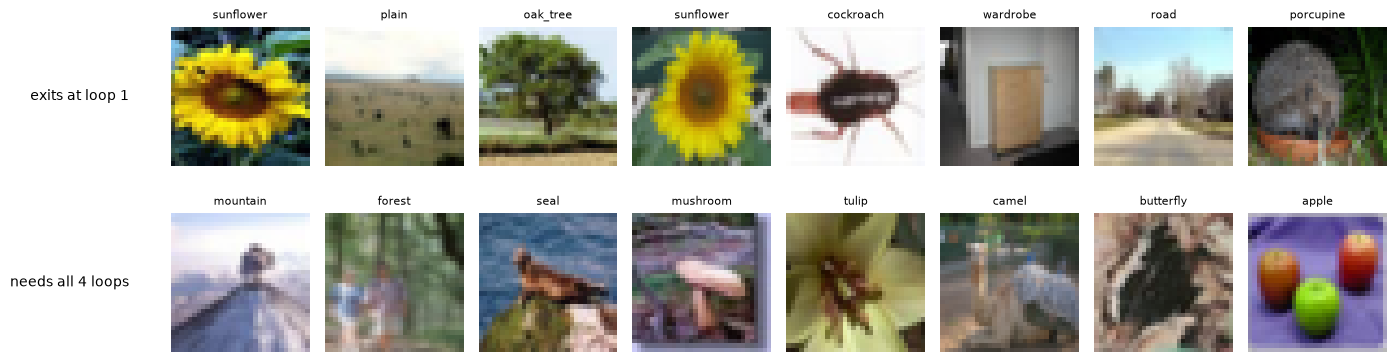

In [18]:
#@title Exit histogram and easy vs hard images
test_probs, test_labels = {}, None
exit_steps = {}
for key in ['A1_looped', 'A9_self_distill']:
    test_probs[key], test_labels = collect_loop_probs(models[key], test_dl, DEPTH)
    exit_steps[key] = simulate_exit(test_probs[key], test_labels, TAU[key], loops=BEST_LOOPS[key])[2]

width = 0.4
for i, key in enumerate(exit_steps):
    counts = torch.bincount(exit_steps[key], minlength=DEPTH + 1)[1:]
    plt.bar([s + i * width for s in range(1, DEPTH + 1)], counts.tolist(), width=width, label=f'{key} (tau={TAU[key]})')
plt.xlabel('exit loop'); plt.ylabel('test images'); plt.legend(); plt.title('Where images stop')
plt.show()

best = 'A9_self_distill'
exit_step = exit_steps[best]
final_pred = test_probs[best].argmax(-1).gather(0, (exit_step - 1)[None]).squeeze(0)   # answer at the exit loop
for t in range(1, BEST_LOOPS[best] + 1):
    mask = exit_step == t
    if mask.any():
        print(f"{best} exit at loop {t}: {mask.sum().item():5d} images, accuracy {(final_pred[mask] == test_labels[mask]).float().mean().item()*100:5.1f}%")

def denorm(img):
    return (img * torch.tensor(std)[:, None, None] + torch.tensor(mean)[:, None, None]).permute(1, 2, 0).clamp(0, 1)

easy = (exit_step == 1).nonzero().flatten()[:8]
hard = (exit_step == BEST_LOOPS[best]).nonzero().flatten()[:8]
fig, axs = plt.subplots(2, 8, figsize=(14, 4))
for row, idxs, title in [(0, easy, 'exits at loop 1'), (1, hard, f'needs all {BEST_LOOPS[best]} loops')]:
    for ax in axs[row]:
        ax.axis('off')
    for ax, i in zip(axs[row], idxs.tolist()):
        ax.imshow(denorm(test[i][0]))
        ax.set_title(class_names[test_labels[i]], fontsize=8)
    axs[row][0].text(-0.3, 0.5, title, transform=axs[row][0].transAxes, ha='right', va='center')
plt.tight_layout(); plt.show()

### What we saw

With A9's budget of 4 loops and threshold 0.6, 177 test images left after loop 1 and were 80.8% correct. 1,714 left after loop 2 (86.7% correct) and 1,075 after loop 3 (83.4% correct). The other 7,034 used all four loops and were only 39.0% correct. The exit loop really is a difficulty score: the images the model is unsure about are the ones it gets wrong.

## 14. Watch one image make up its mind

Pick any test image and plot the probability of its true class after each loop, for A1 and A9. Easy images jump above the threshold almost immediately. Hard images climb slowly, wobble, or settle on the wrong class. With self-distillation, the A9 curve should usually rise sooner.

If you are in Jupyter or Colab, two sliders let you move through test images and change the threshold. The plots reuse the stored probabilities, so they update instantly. Without `ipywidgets`, the cell shows two hard and two easy images instead.

> **TRY IT** Find an image where A1 and A9 disagree at loop 2. Is it an image you would find hard yourself?

**In pictures:** what the next cell does.

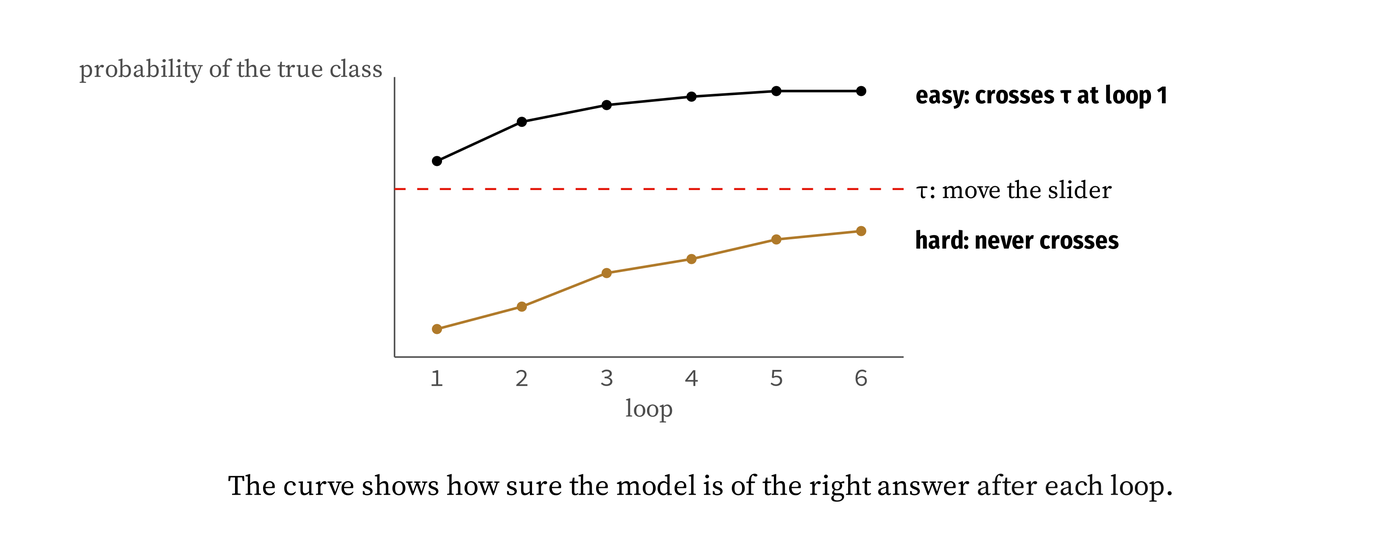

In [19]:
#@title Interactive confidence viewer
def show_image(index=0, tau=TAU['A9_self_distill']):
    label = test_labels[index].item()
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.2))
    a1.imshow(denorm(test[index][0])); a1.axis('off')
    a1.set_title(f'true: {class_names[label]}')
    for key in ['A1_looped', 'A9_self_distill']:
        a2.plot(range(1, DEPTH + 1), test_probs[key][:, index, label], marker='o', label=f'{key}: true class')
    a2.axhline(tau, color='red', alpha=0.4, label=f'tau = {tau}')
    a2.set_ylim(0, 1.02); a2.set_xlabel('loop'); a2.set_ylabel('probability'); a2.legend(fontsize=8)
    plt.tight_layout(); plt.show()

try:
    from ipywidgets import interact, IntSlider, FloatSlider
    interact(show_image,
             index=IntSlider(0, 0, len(test) - 1, 1),
             tau=FloatSlider(value=TAU['A9_self_distill'], min=0.1, max=1.0, step=0.01))
except ImportError:
    for i in hard[:2].tolist() + easy[:2].tolist():
        show_image(i)

interactive(children=(IntSlider(value=0, description='index', max=9999), FloatSlider(value=0.6, description='t…

## 15. Conclusions and next experiments

### What this notebook demonstrates

| Comparison | Our numbers | Lesson |
| --- | --- | --- |
| A0 vs A4 | 2.71M vs 0.49M params, 58.9% vs 55.3% (test) | One block looped six times stores 82% fewer weights and loses about 3.5 points. But it costs the same GMACs: parameter count and speed measure different things |
| A1 vs A2 | 53.1% vs 31.7%, same 0.49M params (test) | The extra loops, not extra parameters, buy the looped model its accuracy |
| A1 vs A4 | 19.3% vs 4.0% after loop 1 (validation) | Training a prediction at every loop is what makes the model useful at every depth. It costs about 2 points at full depth |
| A1 and A9 per loop | best by loop 5 and loop 4 | Looped models can overthink, so the cheapest good answer often comes before the last loop |
| A9 vs A1 | 22.7% vs 19.3% after loop 1 (validation); budget 4 vs 5 | Self-distillation, the DeiT idea inside one model, makes the early loops better, so the model can stop sooner |
| A9 with exit vs A0 | 3.5 vs 6 block passes, 9,604 vs 5,892 images/s | Stopping early is what saves compute: 1.7x fewer GMACs and 1.6x the speed, for about 6 points |

### What it cannot prove

- A small model trained for 60 epochs from scratch is not a ranking of architectures. Research on looped ViTs reports that narrow looped models lose more accuracy than wide ones, so the gap you see here is larger than it would be at ViT-B scale.
- This notebook trains each model once. Our five-seed sweep (see the note at the top) shows how much the numbers move from run to run: about half a point. Treat smaller gaps as noise.
- The stacked ViT is trained without per-layer heads, so it cannot exit early. A fairer comparison gives it early-exit heads too.
- Confidence is a heuristic. A model can be confidently wrong, and the threshold must be checked again whenever the data changes.
- At this accuracy, per-image early exit adds little over a fixed loop budget. Whether it pays off more for a stronger model is something to test, not assume.

### Key terms

| Term | Meaning |
| --- | --- |
| Looped (weight-tied) transformer | A model that applies the same block several times instead of stacking different blocks |
| Step embedding | A learned vector per loop that tells the shared block which loop it is on |
| Deep supervision | Training a prediction at every loop, not just the last |
| Early exit | Stopping when the model's confidence passes a threshold |
| Self-distillation | Using a model's own best prediction (here, its last loop) as the teacher for its weaker predictions |
| GMACs | Billions of multiply-accumulate operations for one image, an estimate of compute |

### Try this

1. **A3, no step embedding.** Remove `self.step` and the `+ self.step_embed(t)` and retrain A1. How does accuracy per loop change?
2. **A5, recall.** Keep the original patch tokens and add them back on every loop, `x = self.block(x + inputs + self.step_embed(t))`. This trick is what lets looped maze solvers keep improving when they loop far longer than they were trained. Does it flatten the curve beyond loop 6?
3. **A8, a CNN teacher.** Replace the self-distillation teacher with a CNN trained on the same dataset, as DeiT does. Is an outside teacher better than the model's own last loop?
4. **Easier data.** Set `DATASET = 'cifar10'`. With only 10 classes, how many images exit at loop 1, and does self-distillation still help?
5. **More loops.** Set `DEPTH = 12`. Does the looped model's parameter count change? Does the stacked model's?
6. **Fight overfitting.** Add `transforms.TrivialAugmentWide()` before `ToTensor()` and `transforms.RandomErasing(p=0.25)` after `Normalize` in `train_tfm`, then delete `./checkpoints` and retrain. Does A0's gap between training loss and validation accuracy shrink? Do more images exit early once the models are more accurate?

<details>
<summary><b>Check your understanding:</b> Why does self-distillation help early exit, even though it does not change the model's architecture?</summary>

Early exit, and a fixed loop budget, only work if the early loops give good answers. Self-distillation trains the early loops to match the last loop's full probability list, so they learn the same class ranking sooner. In our runs this made the first loops about 2 to 4 points more accurate, which let A9 use a budget of 4 loops where A1 needed 5.
</details>